# Dự án House Prices: Khám phá dữ liệu và dự đoán giá nhà

> **Nguồn dữ liệu:** [Kaggle – House Pricing Dataset](https://www.kaggle.com/datasets/alyelbadry/house-pricing-dataset).  
> Notebook sử dụng bộ dữ liệu giao dịch nhà ở King County/Seattle với biến mục tiêu `price`. Cần giữ nguyên tên file CSV đầu vào đã tải từ Kaggle là `house_prices.csv` (hoặc cập nhật `DATA_PATH` ở phần 1). Không nhầm bộ dữ liệu này với cuộc thi *House Prices: Advanced Regression Techniques* (Ames, Iowa), vì hai bộ dữ liệu có cấu trúc và tên biến khác nhau.

## Cấu trúc notebook

1. Khởi tạo môi trường và đọc dữ liệu
2. Data dictionary và kiểm tra cấu trúc
3. Làm sạch dữ liệu và cleaning log
4. Đánh giá chất lượng dữ liệu sau làm sạch
5. Thống kê mô tả
6. Tương quan
7. Phân phối giá và ngoại lệ
8. Phân tích diện tích
9. Chất lượng và số phòng ngủ
10. Phân tích địa lý
11. Kiểm tra bất thường
12. Tổng hợp insight EDA
13. Feature engineering và chia dữ liệu
14. Huấn luyện, so sánh mô hình hồi quy
15. Model evaluation và chẩn đoán sai số


## Mục tiêu nghiên cứu

Notebook thực hiện phân tích dữ liệu giá nhà theo ba hướng chính:

1. **Diện tích:** xem xét mối liên hệ giữa giá bán (`price`), diện tích sinh hoạt (`sqft_living`) và diện tích khu đất (`sqft_lot`).
2. **Chất lượng và vị trí:** mô tả sự khác biệt về giá theo chất lượng xây dựng, số phòng ngủ và tọa độ địa lý (`lat`, `long`).
3. **Machine Learning:** xây dựng mô hình hồi quy dự đoán giá nhà và đánh giá xem nhóm đặc trưng địa lý có giúp cải thiện kết quả hay không.

**Câu hỏi nghiên cứu chính:** Giá nhà trong bộ dữ liệu có mối liên hệ như thế nào với diện tích sinh hoạt, diện tích khu đất, chất lượng xây dựng và vị trí địa lý? Các đặc trưng này dự đoán giá nhà tốt đến mức nào?

> Phân tích tương quan và mô hình dự đoán chỉ phản ánh mối liên hệ trong dữ liệu. Không diễn giải chúng thành quan hệ nhân quả nếu chưa có thiết kế nghiên cứu phù hợp.

## Quy ước

- Biến mục tiêu: `price` (giá bán, USD theo bộ dữ liệu).
- Đơn vị diện tích: square feet (sq ft).
- `sqft_living`: diện tích sinh hoạt bên trong căn nhà, gồm phần trên mặt đất và tầng hầm.
- `sqft_above`: diện tích phần nhà phía trên mặt đất.
- `sqft_basement`: diện tích tầng hầm.
- `sqft_lot`: diện tích toàn bộ khu đất/lô đất.
- `lat`, `long`: vĩ độ và kinh độ của căn nhà.
- `id`: mã định danh, chỉ dùng để truy vết/kiểm tra, không dùng làm đặc trưng dự đoán.

## Tái lập kết quả

- Tải CSV từ đúng trang Kaggle ở trên và đặt cạnh notebook với tên `house_prices.csv`, hoặc sửa `DATA_PATH`.
- Chạy lần lượt từ trên xuống dưới bằng Python 3.
- Thư viện chính: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`.
- Không thay đổi tên cột gốc của dataset. Nếu file tải về có schema khác, cần kiểm tra lại `required_columns` và data dictionary trước khi chạy.
- Nên lưu notebook cùng `README.md`, `data/` (không commit dữ liệu nếu điều khoản nguồn không cho phép), và `requirements.txt` khi đưa lên GitHub.


## 1. Khởi tạo môi trường và đọc dữ liệu

**Chức năng của cell code bên dưới**

- Import các thư viện dùng cho xử lý dữ liệu, trực quan hóa và hiển thị bảng.
- Đọc file `house_prices.csv` vào DataFrame `df_raw`; tạo bản sao `df` để thực hiện các bước xử lý mà vẫn giữ bản dữ liệu ban đầu.
- In kích thước, số ô thiếu, số dòng trùng toàn bộ và một số dòng đầu để xác nhận file đã được đọc đúng.

**Đầu vào:** `house_prices.csv` đặt cùng thư mục với notebook.

**Đầu ra:** `df_raw` (dữ liệu gốc) và `df` (bản làm việc).

In [3]:
# 1. Khởi tạo môi trường và đọc dữ liệu
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from pathlib import Path

# Cấu hình hiển thị để các bảng số liệu dễ đọc hơn.
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlepad'] = 12
sns.set_theme(style='whitegrid', context='notebook')

# Đường dẫn dữ liệu: đổi DATA_PATH nếu file CSV nằm ở thư mục khác.
DATA_PATH = 'house_prices.csv'
data_path = Path(DATA_PATH)

if not data_path.is_absolute():
    candidates = [
        Path.cwd() / data_path,
        Path.cwd() / 'data' / data_path,
        Path.cwd().parent / data_path,
        Path.cwd().parent / 'data' / data_path,
    ]

    matches = [p for p in candidates if p.is_file()]
    if not matches:
        matches = list(Path.cwd().rglob(data_path.name))

    if not matches:
        raise FileNotFoundError(
            f"Không tìm thấy '{data_path.name}'. Đặt file vào thư mục notebook "
            f"hoặc thư mục 'data/', hoặc cập nhật DATA_PATH."
        )

    data_path = matches[0]

DATA_PATH = str(data_path)
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

# Kiểm tra nhanh trạng thái dữ liệu sau khi đọc.
initial_overview = pd.DataFrame({
    'Thông tin': [
        'Số dòng',
        'Số cột',
        'Số ô thiếu',
        'Số dòng trùng toàn bộ các cột'
    ],
    'Giá trị': [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum())
    ]
})

display(initial_overview)
display(df.head())

print(f'Đã đọc dữ liệu thành công: {DATA_PATH}')

,Thông tin,Giá trị
0,Số dòng,21613
1,Số cột,21
2,Số ô thiếu,0
3,Số dòng trùng toàn bộ các cột,0


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,"221,900.00",3,1.00,1180,5650,1.00,N,0,Average,7,1180,0,1955,0,98178,47.51,-122.26,1340,5650
1,6414100192,20141209T000000,"538,000.00",3,2.25,2570,7242,2.00,N,0,Average,7,2170,400,1951,1991,98125,47.72,-122.32,1690,7639
2,5631500400,20150225T000000,"180,000.00",2,1.00,770,10000,1.00,N,0,Average,6,770,0,1933,0,98028,47.74,-122.23,2720,8062
3,2487200875,20141209T000000,"604,000.00",4,3.00,1960,5000,1.00,N,0,Very Good,7,1050,910,1965,0,98136,47.52,-122.39,1360,5000
4,1954400510,20150218T000000,"510,000.00",3,2.00,1680,8080,1.00,N,0,Average,8,1680,0,1987,0,98074,47.62,-122.05,1800,7503


Đã đọc dữ liệu thành công: c:\Dev\KHDL\archive\house_prices.csv


## 2. Data dictionary và kiểm tra cấu trúc

Cell code tiếp theo tạo **data dictionary** ngắn gọn cho những cột chính, sau đó kiểm tra xem các cột cần thiết có tồn tại hay không. Việc này giúp xác định đúng ý nghĩa của các biến diện tích, đặc biệt tránh nhầm `sqft_living` với `sqft_lot`.

| Cột | Ý nghĩa | Vai trò trong phân tích |
|---|---|---|
| `id` | Mã định danh bản ghi/căn nhà | Truy vết, kiểm tra trùng; không đưa vào mô hình |
| `date` | Ngày giao dịch | Tạo đặc trưng năm/tháng bán |
| `price` | Giá bán | Biến mục tiêu cần dự đoán |
| `sqft_living` | Diện tích sinh hoạt trong nhà (sq ft), gồm phần trên mặt đất và tầng hầm | Đặc trưng diện tích chính |
| `sqft_above` | Diện tích phần nhà phía trên mặt đất (sq ft) | Mô tả cấu trúc diện tích |
| `sqft_basement` | Diện tích tầng hầm (sq ft) | Mô tả cấu trúc diện tích |
| `sqft_lot` | Diện tích khu đất/lô đất (sq ft) | Đặc trưng diện tích đất |
| `sqft_living15` | Diện tích sinh hoạt trung bình của 15 căn nhà lân cận theo định nghĩa bộ dữ liệu | Đặc trưng khu vực lân cận |
| `sqft_lot15` | Diện tích lô đất trung bình của 15 căn nhà lân cận theo định nghĩa bộ dữ liệu | Đặc trưng khu vực lân cận |
| `grade`, `condition`, `view`, `waterfront` | Các thuộc tính chất lượng/quan sát của căn nhà | Đặc trưng mô tả |
| `zipcode` | Mã ZIP khu vực | Đặc trưng phân loại khu vực |
| `lat`, `long` | Vĩ độ và kinh độ | Phân tích không gian và mô hình |
| `yr_built`, `yr_renovated` | Năm xây dựng và năm cải tạo | Tạo đặc trưng tuổi nhà/cải tạo |

Cell code sẽ kiểm tra các cột cốt lõi và xuất bảng kiểu dữ liệu, số lượng thiếu, số giá trị duy nhất. Nếu thiếu cột bắt buộc, notebook dừng sớm với thông báo cụ thể thay vì chạy tiếp và phát sinh lỗi khó hiểu.

In [4]:
# 2. Data dictionary và kiểm tra cấu trúc dữ liệu
required_columns = [
    'id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living',
    'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade',
    'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated',
    'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15'
]

missing_required_columns = [col for col in required_columns if col not in df.columns]
if missing_required_columns:
    raise ValueError(
        'File dữ liệu đang thiếu các cột bắt buộc: '
        + ', '.join(missing_required_columns)
    )

# Từ điển mô tả các biến trọng tâm của đề tài.
data_dictionary = pd.DataFrame([
    ('id', 'Mã định danh bản ghi/căn nhà', 'Mã định danh; không dùng để dự đoán'),
    ('date', 'Ngày giao dịch bán nhà', 'Tạo năm và tháng bán'),
    ('price', 'Giá bán (USD)', 'Biến mục tiêu'),
    ('bedrooms', 'Số phòng ngủ', 'Đặc trưng số lượng phòng'),
    ('bathrooms', 'Số phòng tắm', 'Đặc trưng số lượng phòng'),
    ('floors', 'Số tầng của căn nhà', 'Đặc trưng cấu trúc'),
    ('sqft_living', 'Diện tích sinh hoạt trong nhà (sq ft), gồm phần trên mặt đất và tầng hầm', 'Phân tích diện tích nhà'),
    ('sqft_above', 'Diện tích phần nhà phía trên mặt đất (sq ft)', 'Thành phần diện tích sinh hoạt'),
    ('sqft_basement', 'Diện tích tầng hầm (sq ft)', 'Thành phần diện tích sinh hoạt'),
    ('sqft_lot', 'Diện tích khu đất/lô đất (sq ft)', 'Phân tích diện tích đất'),
    ('sqft_living15', 'Diện tích sinh hoạt của nhóm 15 căn lân cận theo định nghĩa bộ dữ liệu', 'Đặc trưng khu vực lân cận'),
    ('sqft_lot15', 'Diện tích lô đất của nhóm 15 căn lân cận theo định nghĩa bộ dữ liệu', 'Đặc trưng khu vực lân cận'),
    ('grade', 'Mức đánh giá chất lượng xây dựng/hoàn thiện', 'Đặc trưng chất lượng'),
    ('condition', 'Tình trạng tổng thể của căn nhà (thang điểm số 1–5 trong dữ liệu)', 'Đặc trưng thứ bậc dạng số'),
    ('view', 'Mức đánh giá tầm nhìn', 'Đặc trưng có thứ tự'),
    ('waterfront', 'Cờ nhị phân: 1 = có mặt nước, 0 = không', 'Đặc trưng nhị phân dạng số'),
    ('zipcode', 'Mã ZIP khu vực', 'Đặc trưng khu vực dạng phân loại'),
    ('lat', 'Vĩ độ', 'Đặc trưng tọa độ địa lý'),
    ('long', 'Kinh độ', 'Đặc trưng tọa độ địa lý'),
    ('yr_built', 'Năm xây dựng', 'Tạo tuổi nhà tại thời điểm bán'),
    ('yr_renovated', 'Năm cải tạo; 0 biểu thị không có năm cải tạo được ghi nhận', 'Tạo đặc trưng cải tạo')
], columns=['Tên cột', 'Giải thích', 'Vai trò'])

display(data_dictionary)

# Tạo hồ sơ dữ liệu để kiểm tra kiểu dữ liệu và mức độ đầy đủ của từng cột.
data_profile = pd.DataFrame({
    'Kiểu dữ liệu': df.dtypes.astype(str),
    'Số giá trị thiếu': df.isna().sum(),
    'Tỷ lệ thiếu (%)': (df.isna().mean() * 100).round(2),
    'Số giá trị duy nhất': df.nunique(dropna=True)
}).sort_values(['Số giá trị thiếu', 'Số giá trị duy nhất'], ascending=[False, True])

display(data_profile)
print(f'Tổng số biến: {df.shape[1]} | Tổng số quan sát: {df.shape[0]:,}')

# Kiểm tra miền giá trị các biến thứ bậc/nhị phân theo mã hóa số của dataset.
coded_value_checks = {
    'waterfront': sorted(df['waterfront'].dropna().unique().tolist()),
    'view': sorted(df['view'].dropna().unique().tolist()),
    'condition': sorted(df['condition'].dropna().unique().tolist()),
    'grade': sorted(df['grade'].dropna().unique().tolist())
}
print('Các giá trị quan sát được ở biến mã hóa:')
display(pd.Series(coded_value_checks, name='Giá trị quan sát').to_frame())


,Tên cột,Giải thích,Vai trò
0,id,Mã định danh bản ghi/căn nhà,Mã định danh; không dùng để dự đoán
1,date,Ngày giao dịch bán nhà,Tạo năm và tháng bán
2,price,Giá bán (USD),Biến mục tiêu
3,bedrooms,Số phòng ngủ,Đặc trưng số lượng phòng
4,bathrooms,Số phòng tắm,Đặc trưng số lượng phòng
5,floors,Số tầng của căn nhà,Đặc trưng cấu trúc
6,sqft_living,"Diện tích sinh hoạt trong nhà (sq ft), gồm phầ...",Phân tích diện tích nhà
7,sqft_above,Diện tích phần nhà phía trên mặt đất (sq ft),Thành phần diện tích sinh hoạt
8,sqft_basement,Diện tích tầng hầm (sq ft),Thành phần diện tích sinh hoạt
9,sqft_lot,Diện tích khu đất/lô đất (sq ft),Phân tích diện tích đất


,Kiểu dữ liệu,Số giá trị thiếu,Tỷ lệ thiếu (%),Số giá trị duy nhất
waterfront,str,0,0.00,2
view,int64,0,0.00,5
condition,str,0,0.00,5
floors,float64,0,0.00,6
grade,int64,0,0.00,12
bedrooms,int64,0,0.00,13
bathrooms,float64,0,0.00,30
yr_renovated,int64,0,0.00,70
zipcode,int64,0,0.00,70
yr_built,int64,0,0.00,116


Tổng số biến: 21 | Tổng số quan sát: 21,613
Các giá trị quan sát được ở biến mã hóa:


,Giá trị quan sát
waterfront,"[N, Y]"
view,"[0, 1, 2, 3, 4]"
condition,"[Average, Fair, Good, Poor, Very Good]"
grade,"[1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]"


## 3. Kiểm tra trùng lặp, chuẩn hóa và làm sạch dữ liệu

Cell code này xử lý các vấn đề chất lượng dữ liệu trước EDA:

1. **Kiểm tra trùng bản ghi:** so sánh các cột nội dung sau khi bỏ `id`, vì mã định danh khác nhau không có nghĩa hai dòng chắc chắn là hai quan sát khác nhau.
2. **Kiểm tra ID lặp:** thống kê riêng. Không tự động xóa các ID lặp vì một căn nhà có thể xuất hiện trong nhiều giao dịch ở những thời điểm khác nhau.
3. **Chuẩn hóa kiểu dữ liệu:** chuyển `date` sang datetime; làm sạch khoảng trắng ở biến phân loại; chuyển `zipcode` thành chuỗi để tránh xem mã ZIP như một đại lượng liên tục.
4. **Giá trị thiếu:** không điền `price`; các dòng không có biến mục tiêu sẽ bị loại. Giá trị thiếu ở biến đầu vào được giữ lại và ghi vào cleaning log; `SimpleImputer` sẽ học median/mode bên trong Pipeline trên train set/fold để tránh data leakage.
5. **Giá trị không hợp lệ:** áp dụng các ràng buộc cơ bản cho giá, diện tích, số phòng, năm xây dựng và tọa độ. Các giá trị cực trị nhưng vẫn hợp lệ không bị xóa tự động.

Kết quả là `df` đã qua làm sạch và `cleaning_log_df` ghi lại số dòng bị ảnh hưởng cùng lý do xử lý.

**Quyết định về ngoại lệ:** không winsorize/xóa chỉ dựa trên IQR. Với dữ liệu bất động sản, căn nhà có diện tích hoặc giá rất cao có thể là quan sát hợp lệ. Notebook chỉ loại các vi phạm ràng buộc rõ ràng (ví dụ giá không dương, diện tích âm, tọa độ ngoài miền hợp lệ), còn ngoại lệ thống kê được giữ để phân tích và kiểm tra riêng.


In [5]:
# 3. Kiểm tra trùng lặp, chuẩn hóa và làm sạch dữ liệu
rows_before_cleaning = len(df)
cleaning_log = []

# 3.1. Kiểm tra bản ghi trùng mà không dùng cột id.
# id là mã định danh; bỏ id khỏi khóa so sánh giúp phát hiện các dòng
# có toàn bộ thông tin nghiệp vụ giống nhau nhưng mã id khác nhau.
comparison_columns = [col for col in df.columns if col != 'id']
duplicates_without_id = int(df.duplicated(subset=comparison_columns).sum())
rows_before_deduplication = len(df)
df = df.drop_duplicates(subset=comparison_columns, keep='first').copy()
rows_removed_as_duplicates = rows_before_deduplication - len(df)

cleaning_log.append({
    'Vấn đề': 'Bản ghi trùng khi không xét id',
    'Cách xử lý': 'Giữ dòng đầu tiên, loại các dòng trùng nội dung trên những cột còn lại',
    'Số dòng bị ảnh hưởng': rows_removed_as_duplicates,
    'Lý do / kiểm chứng': 'id chỉ là mã định danh; các bản ghi giống hệt về nội dung không nên được tính lặp.'
})

# 3.2. ID lặp được thống kê riêng, không xóa tự động.
repeated_id_count = int(df['id'].duplicated().sum())
repeated_id_records = df.loc[df['id'].duplicated(keep=False)].sort_values('id').copy()
cleaning_log.append({
    'Vấn đề': 'ID xuất hiện nhiều lần',
    'Cách xử lý': 'Chỉ ghi nhận để kiểm tra; không tự động xóa',
    'Số dòng bị ảnh hưởng': repeated_id_count,
    'Lý do / kiểm chứng': 'Một tài sản có thể có nhiều giao dịch; cần xem ngày và giá trước khi quyết định.'
})

# 3.3. Chuẩn hóa ngày giao dịch và các cột dạng phân loại.
date_missing_before_parse = int(df['date'].isna().sum())
df['date'] = pd.to_datetime(df['date'], errors='coerce')
date_parse_failures = int(df['date'].isna().sum()) - date_missing_before_parse

# waterfront, view, condition, grade là các biến mã hóa bằng số trong dataset.
# Không chuyển chúng thành chuỗi; nếu ép chuỗi rồi map nhãn N/Y hoặc Poor/Good
# sẽ làm mất dữ liệu vì file gốc lưu các mã 0/1 và thang điểm số.
for col in ['waterfront', 'view', 'condition', 'grade']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Chuẩn hóa khoảng trắng ở các cột văn bản; chuỗi rỗng được xem là thiếu.
text_columns = df.select_dtypes(include=['object', 'string']).columns.tolist()
for col in text_columns:
    cleaned_text = df[col].astype('string').str.strip().replace('', pd.NA)
    df[col] = cleaned_text.astype(object).where(cleaned_text.notna(), np.nan)

# ZIP code là mã khu vực, không phải đại lượng liên tục.
zipcode_cleaned = df['zipcode'].astype('string').str.strip()
df['zipcode'] = zipcode_cleaned.astype(object).where(zipcode_cleaned.notna(), np.nan)

if date_parse_failures > 0:
    cleaning_log.append({
        'Vấn đề': 'Ngày giao dịch không chuyển đổi được',
        'Cách xử lý': 'Chuyển thành NaT; xử lý như dữ liệu thiếu ở bước kế tiếp',
        'Số dòng bị ảnh hưởng': date_parse_failures,
        'Lý do / kiểm chứng': 'Dùng errors=coerce để nhận diện giá trị ngày không đúng định dạng.'
    })

# 3.4. Không tự điền biến mục tiêu price. Dòng không có price không dùng được
# trong bài toán học có giám sát nên được loại khỏi tập phân tích/modeling.
missing_target = int(df['price'].isna().sum())
if missing_target > 0:
    df = df.dropna(subset=['price']).copy()
    cleaning_log.append({
        'Vấn đề': 'Thiếu biến mục tiêu price',
        'Cách xử lý': 'Loại các dòng thiếu price',
        'Số dòng bị ảnh hưởng': missing_target,
        'Lý do / kiểm chứng': 'Không thể huấn luyện hoặc đánh giá mô hình khi không có giá thực tế.'
    })

# 3.5. Ghi nhận giá trị thiếu, chưa điền tại bước làm sạch.
# Việc impute đặc trưng đầu vào sẽ được fit bên trong Pipeline trên train/fold
# để tránh rò rỉ dữ liệu từ validation/test vào quá trình huấn luyện.
missing_by_column = df.isna().sum()
for col in missing_by_column[missing_by_column > 0].index:
    missing_count = int(missing_by_column[col])
    cleaning_log.append({
        'Vấn đề': f'Giá trị thiếu ở cột {col}',
        'Cách xử lý': 'Giữ nguyên NaN; impute trong Pipeline khi modeling',
        'Số dòng bị ảnh hưởng': missing_count,
        'Lý do / kiểm chứng': (
            'Không điền bằng thống kê toàn bộ dataset. SimpleImputer sẽ được fit '
            'riêng trên train set hoặc từng training fold.'
        )
    })

# 3.6. Kiểm tra các điều kiện dữ liệu cơ bản.
# Các điều kiện này chỉ loại các giá trị vi phạm ràng buộc rõ ràng,
# không loại các giá nhà/diện tích lớn chỉ vì chúng nằm ngoài vùng phổ biến.
current_year = pd.Timestamp.today().year
sale_year = df['date'].dt.year
invalid_rules = {
    'price <= 0': df['price'] <= 0,
    'bedrooms < 0': df['bedrooms'] < 0,
    'bathrooms < 0': df['bathrooms'] < 0,
    'sqft_living <= 0': df['sqft_living'] <= 0,
    'sqft_lot <= 0': df['sqft_lot'] <= 0,
    'sqft_above < 0': df['sqft_above'] < 0,
    'sqft_basement < 0': df['sqft_basement'] < 0,
    'floors <= 0': df['floors'] <= 0,
    'waterfront không thuộc {0, 1}': df['waterfront'].notna() & ~df['waterfront'].isin([0, 1]),
    'view ngoài khoảng 0-4': df['view'].notna() & ~df['view'].between(0, 4),
    'condition ngoài khoảng 1-5': df['condition'].notna() & ~df['condition'].between(1, 5),
    'grade ngoài khoảng 1-13': df['grade'].notna() & ~df['grade'].between(1, 13),
    'yr_built ngoài khoảng hợp lý': df['yr_built'].notna() & ~df['yr_built'].between(1800, current_year),
    'lat ngoài khoảng -90 đến 90': df['lat'].notna() & ~df['lat'].between(-90, 90),
    'long ngoài khoảng -180 đến 180': df['long'].notna() & ~df['long'].between(-180, 180)
}

invalid_rows = pd.Series(False, index=df.index)
for rule_name, mask in invalid_rules.items():
    mask = mask.fillna(False)
    affected_count = int(mask.sum())
    if affected_count > 0:
        invalid_rows |= mask
    cleaning_log.append({
        'Vấn đề': rule_name,
        'Cách xử lý': 'Loại dòng vi phạm' if affected_count > 0 else 'Không cần loại dòng',
        'Số dòng bị ảnh hưởng': affected_count,
        'Lý do / kiểm chứng': 'Đối chiếu với ràng buộc cơ bản của biến và miền giá trị hợp lệ.'
    })

rows_removed_invalid = int(invalid_rows.sum())
df = df.loc[~invalid_rows].copy()

# Ghi nhận ngoại lệ thống kê để phân tích riêng; không xóa hoặc winsorize tự động.
cleaning_log.append({
    'Vấn đề': 'Giá trị cực trị ở price và các biến diện tích',
    'Cách xử lý': 'Giữ lại; đánh dấu bằng IQR và kiểm tra các trường hợp bất thường ở phần EDA',
    'Số dòng bị ảnh hưởng': 0,
    'Lý do / kiểm chứng': 'Ngoại lệ thống kê không mặc nhiên là dữ liệu sai; cần xem xét ngữ cảnh căn nhà.'
})

cleaning_log_df = pd.DataFrame(cleaning_log)
print(f'Số dòng ban đầu: {rows_before_cleaning:,}')
print(f'Số dòng sau kiểm tra trùng: {len(df) + rows_removed_invalid:,}')
print(f'Số dòng bị loại do điều kiện không hợp lệ: {rows_removed_invalid:,}')
print(f'Số dòng sau làm sạch: {len(df):,}')
display(cleaning_log_df)

if not repeated_id_records.empty:
    print('Một số ID lặp cần kiểm tra theo ngày giao dịch và giá:')
    display(repeated_id_records[['id', 'date', 'price']].head(20))

Số dòng ban đầu: 21,613
Số dòng sau kiểm tra trùng: 21,613
Số dòng bị loại do điều kiện không hợp lệ: 0
Số dòng sau làm sạch: 21,613


,Vấn đề,Cách xử lý,Số dòng bị ảnh hưởng,Lý do / kiểm chứng
0,Bản ghi trùng khi không xét id,"Giữ dòng đầu tiên, loại các dòng trùng nội dun...",0,id chỉ là mã định danh; các bản ghi giống hệt ...
1,ID xuất hiện nhiều lần,Chỉ ghi nhận để kiểm tra; không tự động xóa,177,Một tài sản có thể có nhiều giao dịch; cần xem...
2,Giá trị thiếu ở cột waterfront,Giữ nguyên NaN; impute trong Pipeline khi mode...,21613,Không điền bằng thống kê toàn bộ dataset. Simp...
3,Giá trị thiếu ở cột condition,Giữ nguyên NaN; impute trong Pipeline khi mode...,21613,Không điền bằng thống kê toàn bộ dataset. Simp...
4,price <= 0,Không cần loại dòng,0,Đối chiếu với ràng buộc cơ bản của biến và miề...
5,bedrooms < 0,Không cần loại dòng,0,Đối chiếu với ràng buộc cơ bản của biến và miề...
6,bathrooms < 0,Không cần loại dòng,0,Đối chiếu với ràng buộc cơ bản của biến và miề...
7,sqft_living <= 0,Không cần loại dòng,0,Đối chiếu với ràng buộc cơ bản của biến và miề...
8,sqft_lot <= 0,Không cần loại dòng,0,Đối chiếu với ràng buộc cơ bản của biến và miề...
9,sqft_above < 0,Không cần loại dòng,0,Đối chiếu với ràng buộc cơ bản của biến và miề...


Một số ID lặp cần kiểm tra theo ngày giao dịch và giá:


,id,date,price
2497,1000102,20150422T000000,"300,000.00"
2496,1000102,20140916T000000,"280,000.00"
16814,7200179,20141016T000000,"150,000.00"
16815,7200179,20150424T000000,"175,000.00"
11434,109200390,20141020T000000,"250,000.00"
11433,109200390,20140820T000000,"245,000.00"
12418,123039336,20141208T000000,"244,900.00"
12417,123039336,20140611T000000,"148,000.00"
7793,251300110,20150114T000000,"358,000.00"
7792,251300110,20140731T000000,"225,000.00"


## 4. Đánh giá chất lượng dữ liệu sau làm sạch

Cell code này tổng hợp trước/sau làm sạch, số dòng bị loại, số ô thiếu còn lại, số bản ghi trùng khi bỏ `id` và số ID lặp còn lại. Bảng giúp người đọc thấy rõ dữ liệu đã thay đổi như thế nào thay vì chỉ xem một câu mô tả.

**Lưu ý:** ID lặp được báo cáo riêng và không đồng nghĩa với bản ghi trùng. Các giao dịch khác ngày hoặc khác giá của cùng một căn nhà cần được giữ lại nếu dữ liệu thể hiện những lần bán khác nhau.

In [6]:
# 4. Đánh giá chất lượng dữ liệu sau làm sạch
final_duplicate_without_id = int(
    df.duplicated(subset=[col for col in df.columns if col != 'id']).sum()
)
final_duplicate_id_count = int(df['id'].duplicated().sum())

quality_summary = pd.DataFrame({
    'Chỉ số': [
        'Số dòng ban đầu',
        'Số dòng sau làm sạch',
        'Số dòng bị loại tổng cộng',
        'Số ô thiếu còn lại',
        'Số bản ghi trùng khi bỏ id',
        'Số ID lặp cần xem xét'
    ],
    'Giá trị': [
        rows_before_cleaning,
        len(df),
        rows_before_cleaning - len(df),
        int(df.isna().sum().sum()),
        final_duplicate_without_id,
        final_duplicate_id_count
    ]
})

display(quality_summary)

missing_after = pd.DataFrame({
    'Số giá trị thiếu': df.isna().sum(),
    'Tỷ lệ thiếu (%)': (df.isna().mean() * 100).round(2)
}).sort_values('Số giá trị thiếu', ascending=False)
display(missing_after)

print('Kiểm tra cuối:')
print(f'- Bản ghi trùng (không xét id): {final_duplicate_without_id}')
print(f'- ID lặp: {final_duplicate_id_count}')
print(f'- Giá trị thiếu: {int(df.isna().sum().sum())}')

,Chỉ số,Giá trị
0,Số dòng ban đầu,21613
1,Số dòng sau làm sạch,21613
2,Số dòng bị loại tổng cộng,0
3,Số ô thiếu còn lại,43226
4,Số bản ghi trùng khi bỏ id,0
5,Số ID lặp cần xem xét,177


,Số giá trị thiếu,Tỷ lệ thiếu (%)
condition,21613,100.00
waterfront,21613,100.00
grade,0,0.00
sqft_living15,0,0.00
long,0,0.00
lat,0,0.00
zipcode,0,0.00
yr_renovated,0,0.00
yr_built,0,0.00
sqft_basement,0,0.00


Kiểm tra cuối:
- Bản ghi trùng (không xét id): 0
- ID lặp: 177
- Giá trị thiếu: 43226


## 5. Thống kê mô tả và thống kê theo nhóm

Cell code này tạo các bảng thống kê có ý nghĩa cho việc đọc dữ liệu:

- Biến số: số quan sát, trung bình, độ lệch chuẩn, min/max, các tứ phân vị, trung vị, skewness và kurtosis.
- Biến phân loại: số nhóm, nhóm xuất hiện nhiều nhất và tần suất.
- Thống kê theo `bedrooms` và `grade`: số căn, giá trung vị, giá trung bình và diện tích sinh hoạt trung bình.

`id` được loại khỏi bảng thống kê định lượng vì chỉ là mã định danh; `zipcode` được xem là biến phân loại. Skewness/kurtosis mô tả hình dạng phân phối, không phải kiểm định giả thuyết hay bằng chứng về nguyên nhân.

In [7]:
# 5. Thống kê mô tả và thống kê theo nhóm
# Không đưa id vào thống kê số vì id không phải đại lượng đo lường.
numeric_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col != 'id'
]
numeric_summary = df[numeric_cols].describe().T
numeric_summary['median'] = df[numeric_cols].median()
numeric_summary['skewness'] = df[numeric_cols].skew()
numeric_summary['kurtosis'] = df[numeric_cols].kurtosis()
numeric_summary['missing'] = df[numeric_cols].isna().sum()

display(numeric_summary.round(3))

categorical_cols = df.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

if categorical_cols:
    categorical_summary = pd.DataFrame({
        'Số giá trị khác nhau': df[categorical_cols].nunique(dropna=True),
        'Giá trị phổ biến nhất': df[categorical_cols].mode(dropna=True).iloc[0],
        'Tần suất giá trị phổ biến nhất': [
            int(df[col].value_counts(dropna=True).iloc[0])
            if not df[col].value_counts(dropna=True).empty else 0
            for col in categorical_cols
        ]
    })
    display(categorical_summary)

# Thống kê theo số phòng ngủ. Tất cả mức đều được giữ để có thể nhận diện
# những mức rất hiếm (ví dụ số phòng ngủ bất thường) trong bước kiểm tra sau.
print('Giá nhà theo số phòng ngủ:')
bedroom_stats = df.groupby('bedrooms', dropna=False).agg(
    so_can=('price', 'size'),
    gia_trung_vi=('price', 'median'),
    gia_trung_binh=('price', 'mean'),
    dien_tich_sinh_hoat_tb=('sqft_living', 'mean')
).sort_index()
display(bedroom_stats.round(2))

print('Giá nhà theo grade:')
grade_stats = df.groupby('grade', dropna=False).agg(
    so_can=('price', 'size'),
    gia_trung_vi=('price', 'median'),
    gia_trung_binh=('price', 'mean'),
    dien_tich_sinh_hoat_tb=('sqft_living', 'mean')
).sort_index()
display(grade_stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis,missing
price,"21,613.00","540,088.14","367,127.20","75,000.00","321,950.00","450,000.00","645,000.00","7,700,000.00","450,000.00",4.02,34.59,0
bedrooms,"21,613.00",3.37,0.93,0.00,3.00,3.00,4.00,33.00,3.00,1.97,49.06,0
bathrooms,"21,613.00",2.12,0.77,0.00,1.75,2.25,2.50,8.00,2.25,0.51,1.28,0
sqft_living,"21,613.00","2,079.90",918.44,290.00,"1,427.00","1,910.00","2,550.00","13,540.00","1,910.00",1.47,5.24,0
sqft_lot,"21,613.00","15,106.97","41,420.51",520.00,"5,040.00","7,618.00","10,688.00","1,651,359.00","7,618.00",13.06,285.08,0
floors,"21,613.00",1.49,0.54,1.00,1.00,1.50,2.00,3.50,1.50,0.62,-0.48,0
waterfront,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21613
view,"21,613.00",0.23,0.77,0.00,0.00,0.00,0.00,4.00,0.00,3.40,10.89,0
condition,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21613
grade,"21,613.00",7.66,1.18,1.00,7.00,7.00,8.00,13.00,7.00,0.77,1.19,0


,Số giá trị khác nhau,Giá trị phổ biến nhất,Tần suất giá trị phổ biến nhất
zipcode,70,98103,602


Giá nhà theo số phòng ngủ:


,so_can,gia_trung_vi,gia_trung_binh,dien_tich_sinh_hoat_tb
bedrooms,,,,
0,13,"288,000.00","409,503.85","1,707.85"
1,199,"299,000.00","317,642.88",884.61
2,2760,"374,000.00","401,372.68","1,239.75"
3,9824,"413,000.00","466,232.08","1,805.84"
4,6882,"549,997.50","635,419.50","2,554.65"
5,1601,"620,000.00","786,599.83","3,047.55"
6,272,"650,000.00","825,520.64","3,284.34"
7,38,"728,580.00","951,184.66","3,974.21"
8,13,"700,000.00","1,105,076.92","3,800.00"


Giá nhà theo grade:


,so_can,gia_trung_vi,gia_trung_binh,dien_tich_sinh_hoat_tb
grade,,,,
1,1,"142,000.00","142,000.00",290.00
3,3,"262,000.00","205,666.67",596.67
4,29,"205,000.00","214,381.03",660.48
5,242,"228,700.00","248,523.97",983.33
6,2038,"275,276.50","301,919.64","1,191.56"
7,8981,"375,000.00","402,590.26","1,689.40"
8,6068,"510,000.00","542,852.77","2,184.75"
9,2615,"720,000.00","773,513.19","2,868.14"
10,1134,"914,327.00","1,071,771.07","3,520.30"


## 6. Tương quan giữa giá nhà và các đặc trưng

Cell code này tính tương quan Pearson giữa `price` và các biến số/biến thứ bậc được chọn, đồng thời vẽ heatmap. `condition` và `waterfront` được mã hóa theo quy ước có giải thích; `zipcode` không đưa vào Pearson vì đây là mã khu vực, không phải thang đo liên tục.

Cần đọc hệ số tương quan như mức độ liên hệ tuyến tính trong mẫu dữ liệu, không phải tỷ lệ phần trăm tác động hay quan hệ nhân quả.

**Giới hạn biến quan sát:** dataset hiện tại không có các trường `education`, `gender` hoặc `marital_status`. Vì vậy, notebook không tự bổ sung các biến này và không thể phân tích tương quan theo nhân khẩu học nếu không có nguồn dữ liệu bổ sung hợp pháp, có định nghĩa và cùng phạm vi quan sát.


,Tương quan Pearson với price
sqft_living,0.70
grade,0.67
sqft_above,0.61
sqft_living15,0.58
bathrooms,0.53
view,0.40
sqft_basement,0.32
bedrooms,0.31
lat,0.31
floors,0.26


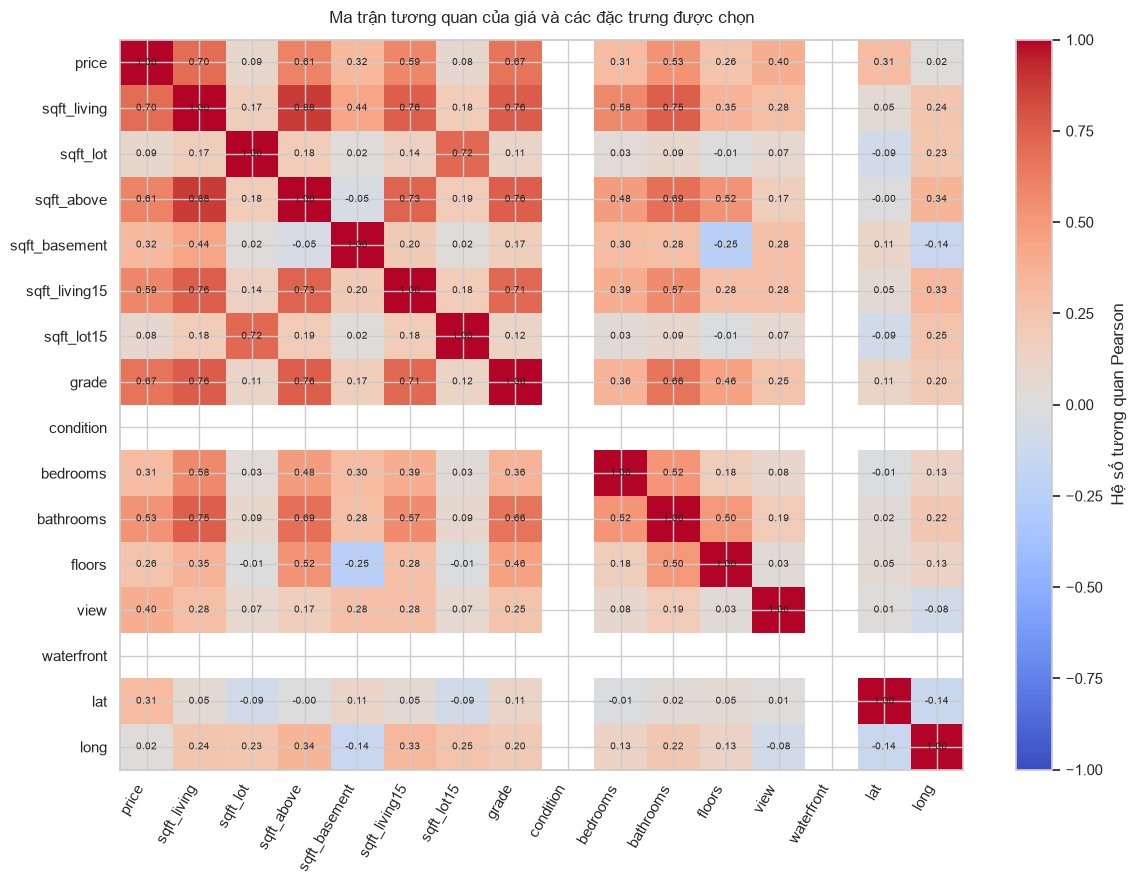

In [8]:
# 6. Tương quan giữa giá nhà và diện tích / chất lượng
correlation_columns = [
    'price', 'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement',
    'sqft_living15', 'sqft_lot15', 'grade', 'condition', 'bedrooms',
    'bathrooms', 'floors', 'view', 'waterfront', 'lat', 'long'
]
correlation_columns = [col for col in correlation_columns if col in df.columns]
corr_df = df[correlation_columns].copy()

# Các biến waterfront, condition, view, grade đã được kiểm tra là mã số.
# Giữ nguyên mã hóa gốc; không map N/Y hoặc Poor/Good vì không đúng schema dataset.
for col in correlation_columns:
    if col in corr_df.columns:
        corr_df[col] = pd.to_numeric(corr_df[col], errors='coerce')

corr = corr_df.corr(numeric_only=True)
price_correlation = corr['price'].drop('price').sort_values(ascending=False)

display(
    price_correlation.to_frame('Tương quan Pearson với price')
    .round(3)
)

fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=60, ha='right')
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

for row in range(len(corr.index)):
    for col in range(len(corr.columns)):
        value = corr.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f'{value:.2f}', ha='center', va='center', fontsize=7)

fig.colorbar(image, ax=ax, label='Hệ số tương quan Pearson')
ax.set_title('Ma trận tương quan của giá và các đặc trưng được chọn')
fig.tight_layout()
plt.show()

## 7. Phân phối giá nhà và phát hiện ngoại lệ bằng IQR

Cell code này trực quan hóa phân phối `price` bằng histogram và boxplot, sau đó tính các ngưỡng IQR:

- IQR = Q3 − Q1.
- Ngưỡng dưới = Q1 − 1.5 × IQR.
- Ngưỡng trên = Q3 + 1.5 × IQR.

IQR được áp dụng không chỉ cho giá nhà mà còn cho các biến số quan trọng như `sqft_living`, `sqft_lot`, `sqft_above`, `sqft_basement`, `bedrooms` và `bathrooms`. Một quan sát nằm ngoài ngưỡng chỉ là **ứng viên ngoại lệ thống kê**, không tự động là dữ liệu sai. Vì vậy notebook giữ nguyên các dòng này để kiểm tra ở bước tiếp theo.

C:\Users\admin\AppData\Local\Temp\ipykernel_25228\2905345483.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df['price'].dropna(), vert=False)


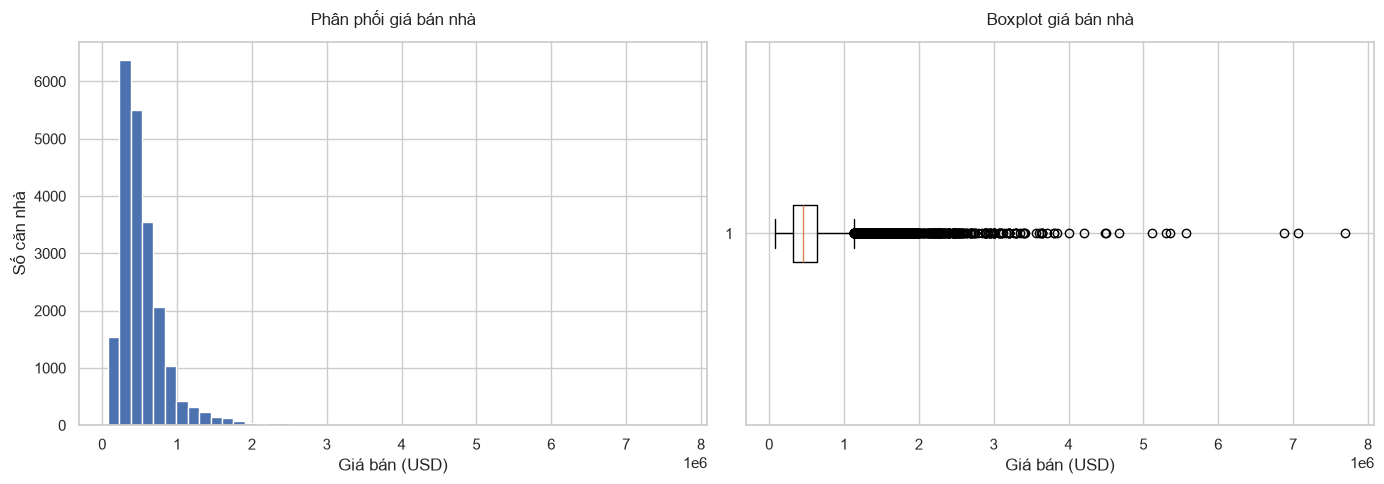

,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Ngoại lệ dưới,Ngoại lệ trên,Tổng ứng viên ngoại lệ
Biến,,,,,,,,
price,"321,950.00","645,000.00","323,050.00","-162,625.00","1,129,575.00",0,1146,1146
sqft_living,"1,427.00","2,550.00","1,123.00",-257.50,"4,234.50",0,572,572
sqft_lot,"5,040.00","10,688.00","5,648.00","-3,432.00","19,160.00",0,2425,2425
sqft_above,"1,190.00","2,210.00","1,020.00",-340.00,"3,740.00",0,611,611
sqft_basement,0.00,560.00,560.00,-840.00,"1,400.00",0,496,496
bedrooms,3.00,4.00,1.00,1.50,5.50,212,334,546
bathrooms,1.75,2.50,0.75,0.62,3.62,14,557,571


C:\Users\admin\AppData\Local\Temp\ipykernel_25228\2905345483.py:58: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
C:\Users\admin\AppData\Local\Temp\ipykernel_25228\2905345483.py:58: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
C:\Users\admin\AppData\Local\Temp\ipykernel_25228\2905345483.py:58: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col].dropna(), vert=False)
C:\Users\admin\AppData\Local\Temp\ipykernel_25228\2905345483.py:58: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'verti

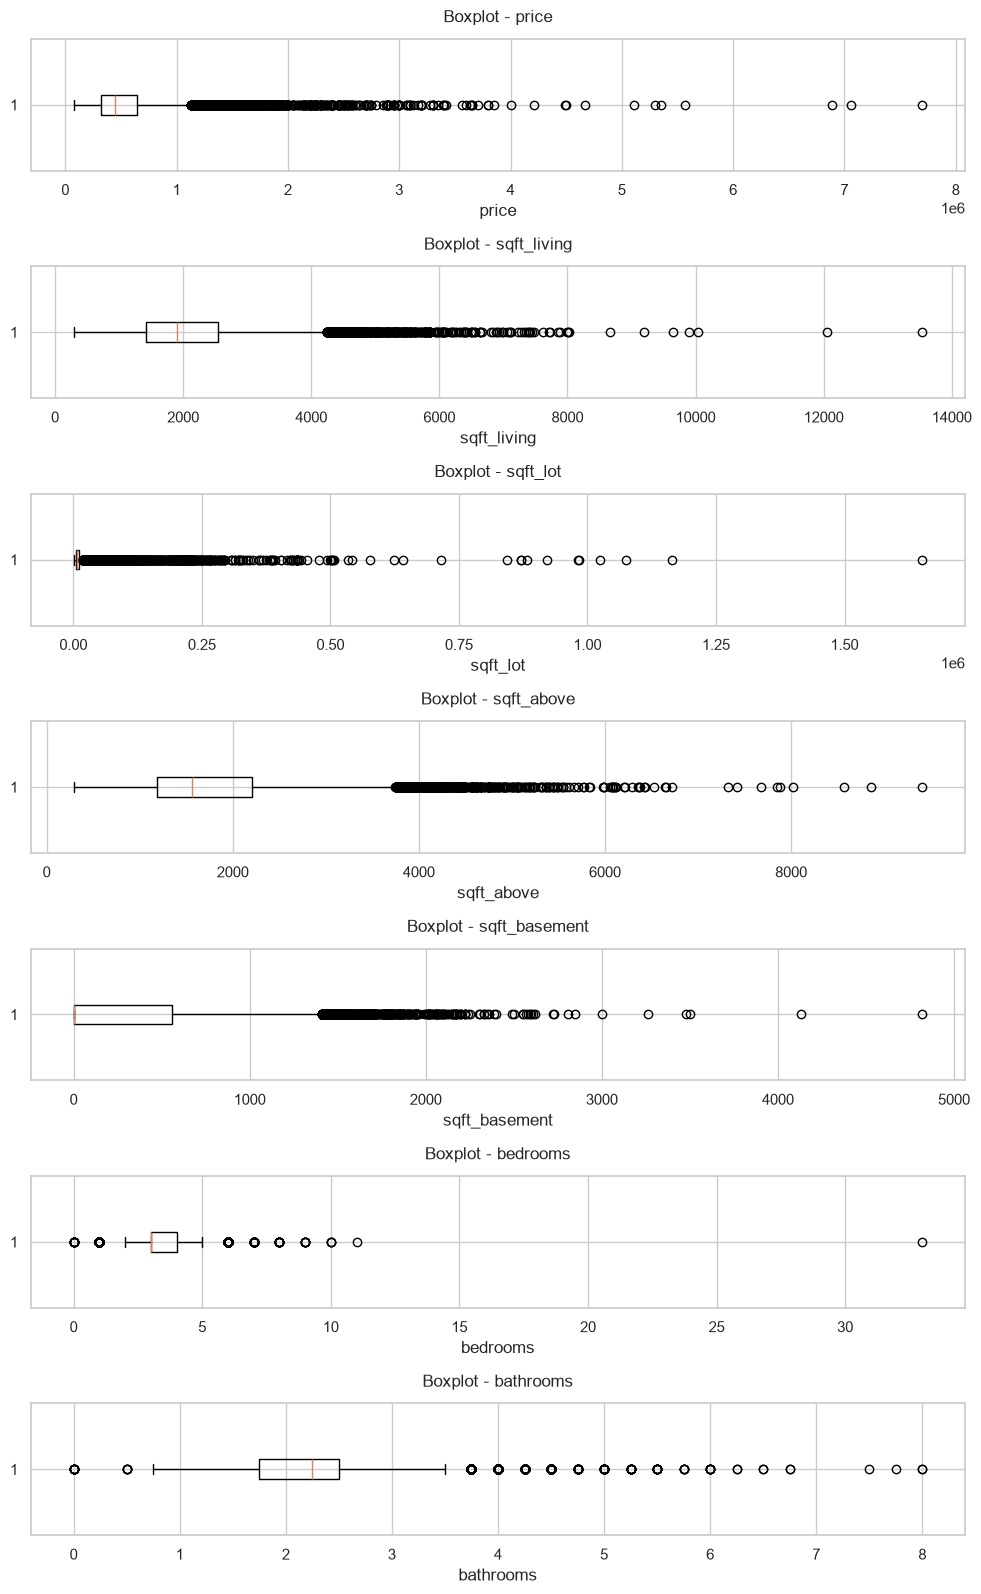

Lưu ý: IQR chỉ đánh dấu các quan sát cần xem xét; không xóa/winsorize tự động.


In [9]:
# 7. Phân phối giá nhà và kiểm tra ngoại lệ bằng IQR
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['price'], bins=50, edgecolor='white')
axes[0].set_title('Phân phối giá bán nhà')
axes[0].set_xlabel('Giá bán (USD)')
axes[0].set_ylabel('Số căn nhà')

axes[1].boxplot(df['price'].dropna(), vert=False)
axes[1].set_title('Boxplot giá bán nhà')
axes[1].set_xlabel('Giá bán (USD)')

plt.tight_layout()
plt.show()

# Áp dụng IQR cho nhiều cột, không chỉ price.
outlier_columns = [
    'price', 'sqft_living', 'sqft_lot', 'sqft_above',
    'sqft_basement', 'bedrooms', 'bathrooms'
]
outlier_columns = [col for col in outlier_columns if col in df.columns]
outlier_rows = []

for col in outlier_columns:
    values = df[col].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr_value = q3 - q1
    lower_fence = q1 - 1.5 * iqr_value
    upper_fence = q3 + 1.5 * iqr_value
    lower_count = int((values < lower_fence).sum())
    upper_count = int((values > upper_fence).sum())

    outlier_rows.append({
        'Biến': col,
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr_value,
        'Ngưỡng dưới': lower_fence,
        'Ngưỡng trên': upper_fence,
        'Ngoại lệ dưới': lower_count,
        'Ngoại lệ trên': upper_count,
        'Tổng ứng viên ngoại lệ': lower_count + upper_count
    })

iqr_outlier_summary = pd.DataFrame(outlier_rows).set_index('Biến')
display(iqr_outlier_summary.round(2))

# Vẽ boxplot riêng từng biến để tránh các thang đo khác nhau làm biểu đồ khó đọc.
fig, axes = plt.subplots(
    nrows=len(outlier_columns), ncols=1,
    figsize=(10, max(3, 2.3 * len(outlier_columns)))
)
if len(outlier_columns) == 1:
    axes = [axes]

for ax, col in zip(axes, outlier_columns):
    ax.boxplot(df[col].dropna(), vert=False)
    ax.set_title(f'Boxplot - {col}')
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

print('Lưu ý: IQR chỉ đánh dấu các quan sát cần xem xét; không xóa/winsorize tự động.')

## 8. Phân tích riêng diện tích sinh hoạt và diện tích khu đất

Đây là phần trả lời trực tiếp câu hỏi về hai biến diện tích:

- `sqft_living`: diện tích sinh hoạt trong căn nhà, không phải diện tích lô đất.
- `sqft_lot`: diện tích toàn bộ khu đất chứa căn nhà.

Cell code vẽ hai scatter plot riêng: giá theo diện tích sinh hoạt và giá theo diện tích khu đất. Trục `sqft_lot` dùng thang log để giảm hiện tượng các lô đất rất lớn nén phần lớn điểm dữ liệu vào một vùng nhỏ. Bảng cuối so sánh Pearson và Spearman; Spearman hữu ích khi quan hệ có xu hướng đơn điệu nhưng phân phối lệch.

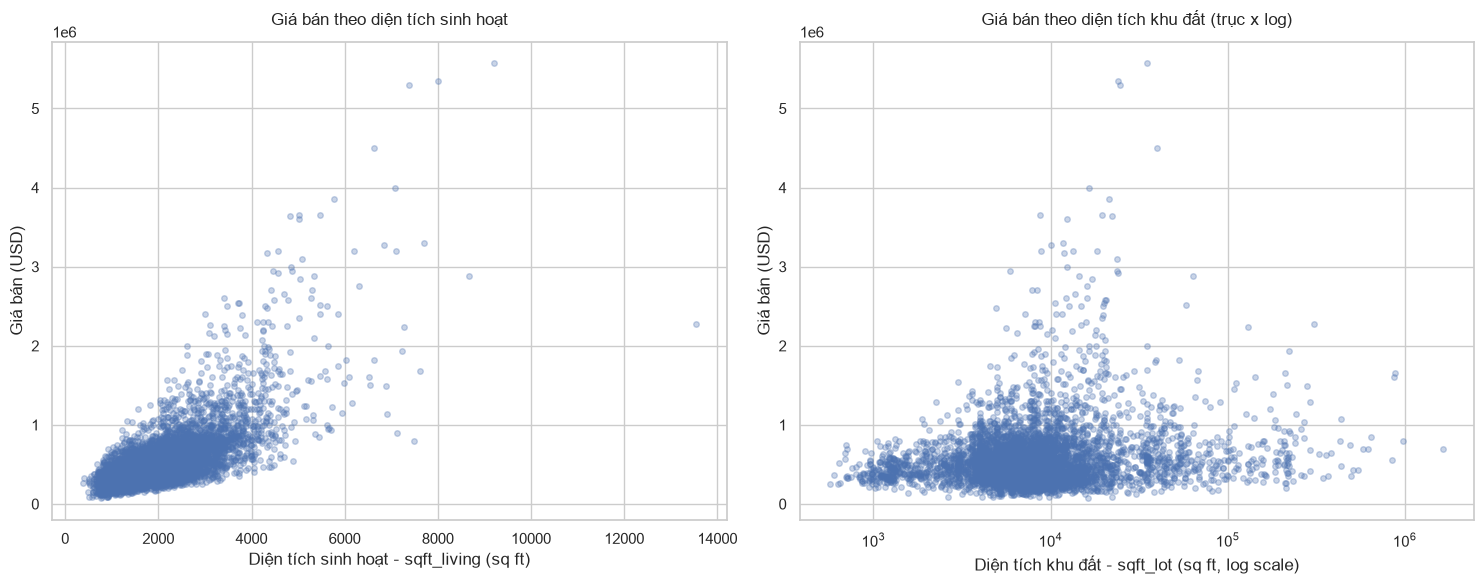

,Pearson,Spearman
sqft_living - diện tích sinh hoạt,0.70,0.64
sqft_lot - diện tích khu đất,0.09,0.07


In [10]:
# 8. Phân tích giá nhà theo sqft_living và sqft_lot
area_sample = df.sample(n=min(6000, len(df)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Biểu đồ 1: diện tích sinh hoạt so với giá bán.
axes[0].scatter(
    area_sample['sqft_living'], area_sample['price'],
    alpha=0.30, s=16
)
axes[0].set_title('Giá bán theo diện tích sinh hoạt')
axes[0].set_xlabel('Diện tích sinh hoạt - sqft_living (sq ft)')
axes[0].set_ylabel('Giá bán (USD)')

# Biểu đồ 2: diện tích khu đất so với giá bán; trục x log giúp đọc vùng giá trị rộng.
axes[1].scatter(
    area_sample['sqft_lot'], area_sample['price'],
    alpha=0.30, s=16
)
axes[1].set_xscale('log')
axes[1].set_title('Giá bán theo diện tích khu đất (trục x log)')
axes[1].set_xlabel('Diện tích khu đất - sqft_lot (sq ft, log scale)')
axes[1].set_ylabel('Giá bán (USD)')

plt.tight_layout()
plt.show()

# So sánh hai thước đo tương quan để không chỉ phụ thuộc Pearson.
area_correlation = pd.DataFrame({
    'Pearson': [
        df['price'].corr(df['sqft_living'], method='pearson'),
        df['price'].corr(df['sqft_lot'], method='pearson')
    ],
    'Spearman': [
        df['price'].corr(df['sqft_living'], method='spearman'),
        df['price'].corr(df['sqft_lot'], method='spearman')
    ]
}, index=['sqft_living - diện tích sinh hoạt', 'sqft_lot - diện tích khu đất'])

display(area_correlation.round(3))

## 9. Giá nhà theo chất lượng xây dựng và số phòng ngủ

Cell code này bổ sung hai góc nhìn phân nhóm:

- Theo `grade`: so sánh số lượng căn nhà và giá trung vị ở từng mức chất lượng.
- Theo `bedrooms`: so sánh số căn, giá trung vị và diện tích sinh hoạt trung bình theo số phòng ngủ.

Sử dụng giá trung vị bên cạnh giá trung bình để giảm ảnh hưởng của một số căn có mức giá rất cao. Các nhóm có ít quan sát cần được diễn giải thận trọng.

,grade,so_can,gia_trung_vi,gia_trung_binh
0,1,1,"142,000.00","142,000.00"
1,3,3,"262,000.00","205,666.67"
2,4,29,"205,000.00","214,381.03"
3,5,242,"228,700.00","248,523.97"
4,6,2038,"275,276.50","301,919.64"
5,7,8981,"375,000.00","402,590.26"
6,8,6068,"510,000.00","542,852.77"
7,9,2615,"720,000.00","773,513.19"
8,10,1134,"914,327.00","1,071,771.07"
9,11,399,"1,284,000.00","1,496,841.73"


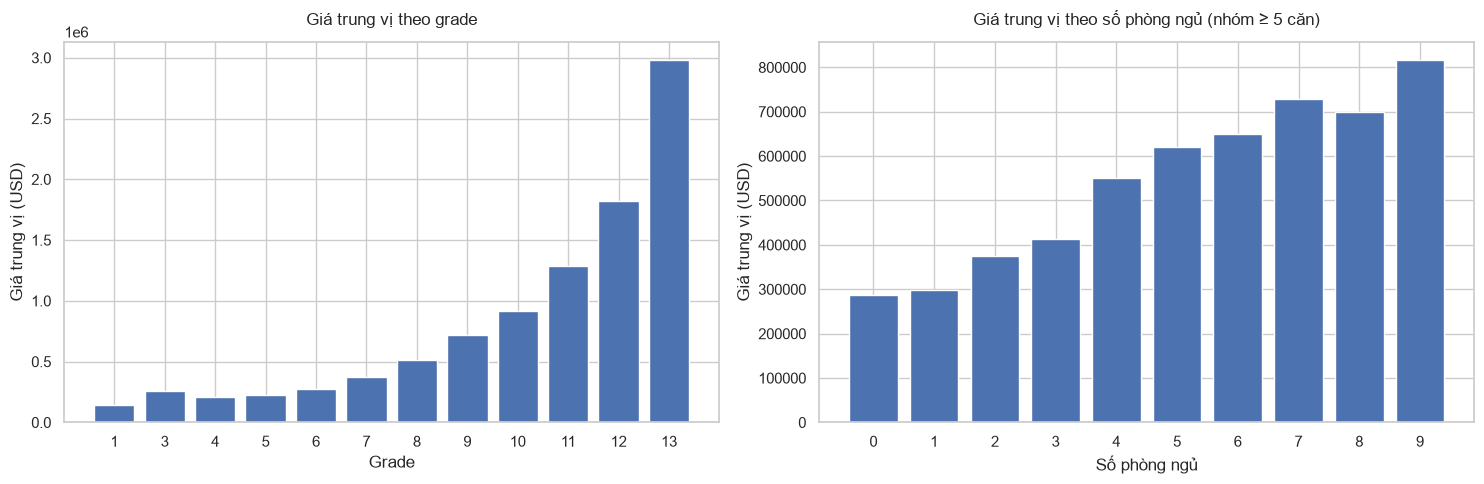

,bedrooms,so_can,gia_trung_vi,gia_trung_binh,dien_tich_sinh_hoat_tb
0,0,13,"288,000.00","409,503.85","1,707.85"
1,1,199,"299,000.00","317,642.88",884.61
2,2,2760,"374,000.00","401,372.68","1,239.75"
3,3,9824,"413,000.00","466,232.08","1,805.84"
4,4,6882,"549,997.50","635,419.50","2,554.65"
5,5,1601,"620,000.00","786,599.83","3,047.55"
6,6,272,"650,000.00","825,520.64","3,284.34"
7,7,38,"728,580.00","951,184.66","3,974.21"
8,8,13,"700,000.00","1,105,076.92","3,800.00"
9,9,6,"817,000.00","893,999.83","3,775.00"


In [11]:
# 9. Giá nhà theo grade và số phòng ngủ
# Thống kê theo grade.
grade_stats = df.groupby('grade').agg(
    so_can=('price', 'size'),
    gia_trung_vi=('price', 'median'),
    gia_trung_binh=('price', 'mean')
).reset_index()
display(grade_stats.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(grade_stats['grade'].astype(str), grade_stats['gia_trung_vi'])
axes[0].set_title('Giá trung vị theo grade')
axes[0].set_xlabel('Grade')
axes[0].set_ylabel('Giá trung vị (USD)')

# Thống kê theo số phòng ngủ; các nhóm rất ít mẫu vẫn được giữ trong bảng.
bedroom_stats = df.groupby('bedrooms').agg(
    so_can=('price', 'size'),
    gia_trung_vi=('price', 'median'),
    gia_trung_binh=('price', 'mean'),
    dien_tich_sinh_hoat_tb=('sqft_living', 'mean')
).reset_index()

# Chỉ vẽ các nhóm có tối thiểu 5 căn để đồ thị không bị chi phối bởi nhóm cực ít mẫu.
bedroom_plot = bedroom_stats[bedroom_stats['so_can'] >= 5].copy()
axes[1].bar(
    bedroom_plot['bedrooms'].astype(str),
    bedroom_plot['gia_trung_vi']
)
axes[1].set_title('Giá trung vị theo số phòng ngủ (nhóm ≥ 5 căn)')
axes[1].set_xlabel('Số phòng ngủ')
axes[1].set_ylabel('Giá trung vị (USD)')

plt.tight_layout()
plt.show()

display(bedroom_stats.round(2))

## 9.1. So sánh giá theo tình trạng, tầm nhìn và mặt nước

Phần này bổ sung góc nhìn theo ba biến có mã hóa số trong dữ liệu gốc:
- `condition`: tình trạng tổng thể (1–5).
- `view`: mức đánh giá tầm nhìn (0–4).
- `waterfront`: 0/1, không/có tiếp giáp mặt nước.

Biểu đồ dùng giá trung vị và số quan sát theo nhóm. Cần xem đồng thời cỡ mẫu; nhóm hiếm có thể có trung vị biến động lớn. Đây là so sánh mô tả, không kết luận rằng một đặc điểm đơn lẻ gây ra chênh lệch giá.


Kiểm tra dữ liệu condition sau bước làm sạch:
 - Kiểu dữ liệu: float64
 - Số giá trị không thiếu: 0
 - Số giá trị thiếu: 21613
 - Các giá trị condition đang có:


,condition,so_luong
0,NaN,21613



Không thể lập bảng giá theo condition: không còn giá trị hợp lệ ở cột condition. Hãy xem bảng kiểm tra condition ở phía trên và xác nhận schema CSV.

Bảng thống kê giá theo view:


,view,so_can,gia_trung_vi,gia_trung_binh,gia_thap_nhat,gia_cao_nhat
0,0,19489,"432,500.00","496,564.19","75,000.00","5,570,000.00"
1,1,332,"690,944.00","812,280.84","217,000.00","3,650,000.00"
2,2,963,"675,000.00","792,400.89","169,317.00","7,062,500.00"
3,3,510,"802,500.00","971,965.27","154,000.00","7,700,000.00"
4,4,319,"1,185,000.00","1,463,711.24","252,000.00","6,885,000.00"



Không thể lập bảng giá theo waterfront: không còn giá trị hợp lệ ở cột waterfront. Hãy xem bảng kiểm tra condition ở phía trên và xác nhận schema CSV.


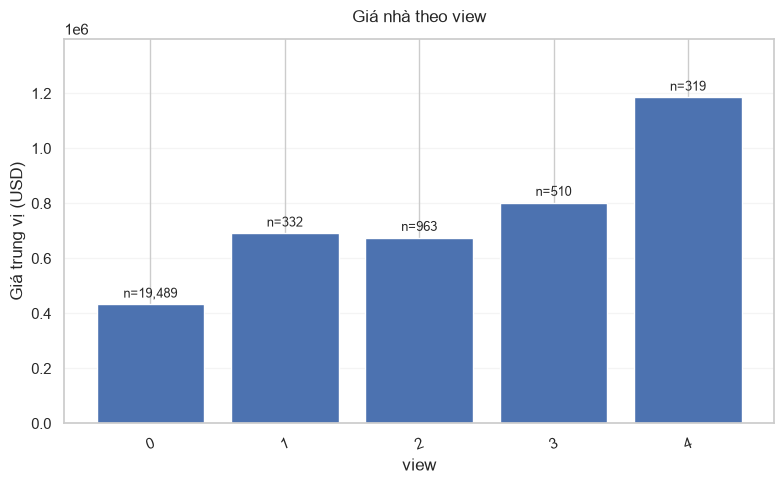


Số dòng có price hợp lệ dùng cho thống kê: 21,613. Cell này không xóa hoặc chỉnh sửa dữ liệu trong df gốc.


In [ ]:
# 9.1. So sánh giá theo condition, view và waterfront
# Sửa lỗi bảng condition rỗng:
# - Không ép condition sang số nếu cột đang là nhãn chữ.
# - Báo cáo số lượng thiếu và các giá trị thực tế có trong cột.
# - Chỉ loại các dòng không có price hợp lệ; không làm thay đổi df gốc.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

comparison_columns = ['condition', 'view', 'waterfront']
missing_columns = [col for col in ['price'] + comparison_columns if col not in df.columns]

if missing_columns:
    raise KeyError(
        'Thiếu cột cần cho thống kê: ' + ', '.join(missing_columns)
    )

plot_data = df[['price'] + comparison_columns].copy()
plot_data['price'] = pd.to_numeric(plot_data['price'], errors='coerce')
plot_data['price'] = plot_data['price'].replace([np.inf, -np.inf], np.nan)
plot_data = plot_data.dropna(subset=['price'])
plot_data = plot_data.loc[plot_data['price'] > 0].copy()

# Chỉ view và waterfront chắc chắn là biến mã số theo định nghĩa dataset.
for col in ['view', 'waterfront']:
    plot_data[col] = pd.to_numeric(plot_data[col], errors='coerce')

# condition được giữ theo đúng kiểu đã xử lý ở cell làm sạch:
# số 1-5 nếu là mã số/nhãn đã ánh xạ; chuỗi nếu dataset dùng nhãn phân loại khác.
if pd.api.types.is_numeric_dtype(plot_data['condition']):
    plot_data['condition'] = pd.to_numeric(plot_data['condition'], errors='coerce')
else:
    plot_data['condition'] = (
        plot_data['condition'].astype('string').str.strip()
        .replace('', pd.NA)
    )

# Chẩn đoán tình trạng cột condition, giúp xác định nguyên nhân nếu không có nhóm.
print('Kiểm tra dữ liệu condition sau bước làm sạch:')
print(' - Kiểu dữ liệu:', df['condition'].dtype)
print(' - Số giá trị không thiếu:', int(df['condition'].notna().sum()))
print(' - Số giá trị thiếu:', int(df['condition'].isna().sum()))
print(' - Các giá trị condition đang có:')
condition_value_counts = df['condition'].value_counts(dropna=False).rename_axis(
    'condition'
).reset_index(name='so_luong')
display(condition_value_counts.head(20))

stats_by_column = {}
for col in comparison_columns:
    temp = plot_data.dropna(subset=[col]).copy()

    if temp.empty:
        print(
            f'\nKhông thể lập bảng giá theo {col}: '
            f'không còn giá trị hợp lệ ở cột {col}. '
            'Hãy xem bảng kiểm tra condition ở phía trên và xác nhận schema CSV.'
        )
        stats_by_column[col] = pd.DataFrame(
            columns=[col, 'so_can', 'gia_trung_vi', 'gia_trung_binh',
                     'gia_thap_nhat', 'gia_cao_nhat']
        )
        continue

    stats = (
        temp.groupby(col, observed=True, dropna=True)
        .agg(
            so_can=('price', 'size'),
            gia_trung_vi=('price', 'median'),
            gia_trung_binh=('price', 'mean'),
            gia_thap_nhat=('price', 'min'),
            gia_cao_nhat=('price', 'max')
        )
        .reset_index()
        .sort_values(col)
    )

    # Diễn giải mã condition theo thang chuẩn King County khi dữ liệu là 1-5.
    if col == 'condition' and pd.api.types.is_numeric_dtype(stats[col]):
        condition_meanings = {
            1: '1 - Poor',
            2: '2 - Fair',
            3: '3 - Average',
            4: '4 - Good',
            5: '5 - Very Good'
        }
        stats.insert(
            1,
            'dien_giai',
            stats[col].map(condition_meanings).fillna(stats[col].astype(str))
        )

    stats_by_column[col] = stats
    print(f'\nBảng thống kê giá theo {col}:')
    display(stats.round(2))

# Vẽ 3 biểu đồ riêng; bảng vẫn được hiển thị ngay cả khi không có dữ liệu cho một nhóm.
for col in comparison_columns:
    stats = stats_by_column[col]
    if stats.empty:
        continue

    labels_source = stats['dien_giai'] if 'dien_giai' in stats.columns else stats[col]
    labels = labels_source.astype(str).tolist()
    values = pd.to_numeric(stats['gia_trung_vi'], errors='coerce').to_numpy(dtype=float)
    counts = stats['so_can'].to_numpy(dtype=int)

    valid = np.isfinite(values)
    labels = [label for label, keep in zip(labels, valid) if keep]
    values = values[valid]
    counts = counts[valid]

    if len(values) == 0:
        print(f'Không có giá trị giá trung vị hợp lệ để vẽ cho {col}.')
        continue

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(labels, values)
    ax.set_title(f'Giá nhà theo {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Giá trung vị (USD)')
    ax.grid(axis='y', alpha=0.2)
    ax.tick_params(axis='x', rotation=20)
    ax.bar_label(
        bars,
        labels=[f'n={n:,}' for n in counts],
        padding=3,
        fontsize=9
    )
    max_value = float(np.max(values))
    if max_value > 0:
        ax.set_ylim(0, max_value * 1.18)
    fig.tight_layout()
    plt.show()

print(
    f'\nSố dòng có price hợp lệ dùng cho thống kê: {len(plot_data):,}. '
    'Cell này không xóa hoặc chỉnh sửa dữ liệu trong df gốc.'
)


## 10. Phân tích vị trí địa lý bằng lat, long và zipcode

Phần này xử lý nhận xét về tọa độ địa lý: notebook cần trực tiếp thể hiện vị trí trong EDA, không chỉ đưa `lat` và `long` vào mô hình.

Cell code sẽ:

1. Vẽ scatter plot theo `long` (kinh độ) và `lat` (vĩ độ), tô màu theo log(1 + giá bán) để quan sát phân bố không gian.
2. Tổng hợp số căn và giá trung vị theo `zipcode`, chỉ hiển thị các khu vực có đủ số quan sát tối thiểu để hạn chế diễn giải từ nhóm quá nhỏ.

Đây là biểu đồ tọa độ từ dữ liệu, không có ranh giới hành chính hay lớp bản đồ nền. Chênh lệch giá giữa khu vực là mô tả trong mẫu, chưa đủ để kết luận vị trí tự nó gây ra chênh lệch giá.

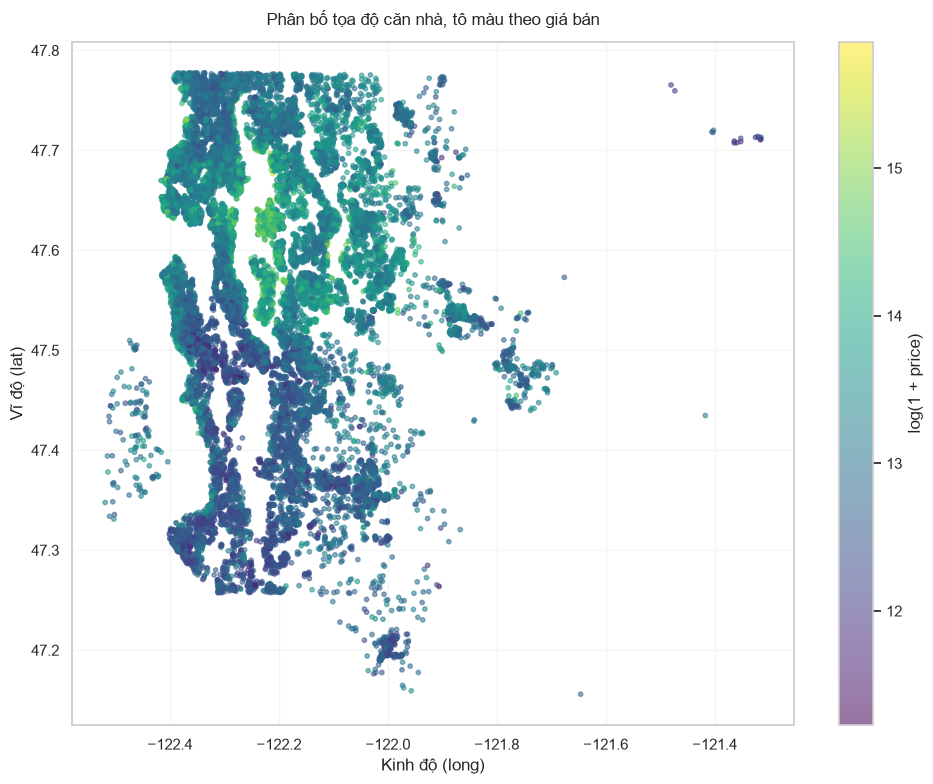

10 khu vực có giá trung vị cao nhất (trong các ZIP có ít nhất 20 căn):


,so_can,gia_trung_vi,gia_trung_binh,lat_trung_vi,long_trung_vi
zipcode,,,,,
98039,50,"1,892,500.00","2,160,606.60",47.62,-122.24
98004,317,"1,150,000.00","1,355,927.08",47.62,-122.20
98040,282,"993,750.00","1,194,230.02",47.56,-122.22
98112,269,"915,000.00","1,095,499.34",47.63,-122.30
98005,168,"765,475.00","810,164.88",47.60,-122.17
98006,498,"760,184.50","859,684.78",47.56,-122.15
98119,184,"744,975.00","849,448.02",47.64,-122.37
98075,359,"739,999.00","790,576.65",47.59,-122.02
98109,109,"736,000.00","879,623.62",47.64,-122.35


10 khu vực có giá trung vị thấp nhất (trong các ZIP có ít nhất 20 căn):


,so_can,gia_trung_vi,gia_trung_binh,lat_trung_vi,long_trung_vi
zipcode,,,,,
98002,199,"235,000.00","234,284.04",47.31,-122.22
98168,269,"235,000.00","240,328.37",47.49,-122.31
98032,125,"249,000.00","251,296.24",47.37,-122.28
98001,362,"260,000.00","280,804.69",47.32,-122.27
98188,136,"264,000.00","289,078.35",47.45,-122.28
98198,280,"265,000.00","302,878.88",47.39,-122.32
98003,280,"267,475.00","294,111.28",47.33,-122.31
98023,499,"268,450.00","286,732.79",47.31,-122.36
98148,57,"278,000.00","284,908.60",47.43,-122.33


Khoảng tọa độ quan sát được: lat [47.1559, 47.7776], long [-122.5190, -121.3150]


In [13]:
# 10. Phân tích vị trí địa lý bằng lat, long và zipcode
geo_data = df.dropna(subset=['lat', 'long', 'price']).copy()
geo_data['log_price'] = np.log1p(geo_data['price'])

fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(
    geo_data['long'],
    geo_data['lat'],
    c=geo_data['log_price'],
    cmap='viridis',
    s=10,
    alpha=0.55
)
fig.colorbar(scatter, ax=ax, label='log(1 + price)')
ax.set_title('Phân bố tọa độ căn nhà, tô màu theo giá bán')
ax.set_xlabel('Kinh độ (long)')
ax.set_ylabel('Vĩ độ (lat)')
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Tổng hợp giá theo mã ZIP; chuyển zipcode thành chuỗi để giữ đúng bản chất mã khu vực.
zipcode_summary = geo_data.groupby('zipcode').agg(
    so_can=('price', 'size'),
    gia_trung_vi=('price', 'median'),
    gia_trung_binh=('price', 'mean'),
    lat_trung_vi=('lat', 'median'),
    long_trung_vi=('long', 'median')
)

# Chỉ xếp hạng khu vực có ít nhất 20 căn trong dữ liệu.
zipcode_summary_reliable = zipcode_summary[zipcode_summary['so_can'] >= 20].copy()
print('10 khu vực có giá trung vị cao nhất (trong các ZIP có ít nhất 20 căn):')
display(zipcode_summary_reliable.sort_values('gia_trung_vi', ascending=False).head(10).round(2))

print('10 khu vực có giá trung vị thấp nhất (trong các ZIP có ít nhất 20 căn):')
display(zipcode_summary_reliable.sort_values('gia_trung_vi', ascending=True).head(10).round(2))

print(
    'Khoảng tọa độ quan sát được: '
    f"lat [{geo_data['lat'].min():.4f}, {geo_data['lat'].max():.4f}], "
    f"long [{geo_data['long'].min():.4f}, {geo_data['long'].max():.4f}]"
)

## 11. Kiểm tra và điều tra các điểm dữ liệu bất thường

IQR ở phần 7 phát hiện các giá trị nằm xa vùng phân phối phổ biến, nhưng không giải thích được vì sao một dòng có thể bất thường. Cell code này kiểm tra thêm các quy tắc có thể đối chiếu trực tiếp với cấu trúc dữ liệu:

- Số phòng ngủ từ 10 trở lên: trường hợp hiếm, cần xác minh (ví dụ giá trị 33 trong dữ liệu gốc).
- Số phòng tắm bằng 0: cần kiểm tra ngữ cảnh bản ghi.
- Năm xây dựng sau năm bán.
- Năm cải tạo nằm sau năm bán hoặc trước năm xây dựng.
- `sqft_living` không xấp xỉ tổng `sqft_above + sqft_basement`.

Cell code đếm số dòng vi phạm từng quy tắc, tạo bảng các dòng cần xem lại và hiển thị một số trường hợp kèm `id`, ngày, giá, diện tích và tọa độ. Các cờ này **không tự động xóa dữ liệu**: người phân tích cần kiểm tra bản ghi gốc hoặc nguồn dữ liệu trước khi kết luận.

**Cách viết Data Storytelling trong báo cáo:** với mỗi insight, ghi đủ (1) câu hỏi, (2) biểu đồ/bảng làm bằng chứng, (3) con số cụ thể, (4) diễn giải có giới hạn, (5) hàm ý thực tiễn. Ví dụ: không viết “vị trí làm giá tăng”; hãy viết “giá trung vị khác nhau giữa các ZIP code trong mẫu, nhưng cần kiểm soát grade, diện tích và chất lượng trước khi quy chênh lệch cho vị trí”.


In [14]:
# 11. Kiểm tra và điều tra các điểm dữ liệu bất thường
sale_year_for_check = df['date'].dt.year

anomaly_conditions = {
    'bedrooms >= 10 (số phòng ngủ rất hiếm)': df['bedrooms'] >= 10,
    'bathrooms = 0 (cần kiểm tra)': df['bathrooms'] == 0,
    'yr_built sau năm bán': df['yr_built'] > sale_year_for_check,
    'yr_renovated sau năm bán': (
        (df['yr_renovated'] > 0) &
        (df['yr_renovated'] > sale_year_for_check)
    ),
    'yr_renovated trước yr_built': (
        (df['yr_renovated'] > 0) &
        (df['yr_renovated'] < df['yr_built'])
    ),
    'sqft_living khác sqft_above + sqft_basement': (
        (df['sqft_living'] - df['sqft_above'] - df['sqft_basement']).abs() > 1
    )
}

# Chuyển kết quả từng quy tắc thành bảng Boolean có cùng index với df.
anomaly_flags = pd.DataFrame({
    rule_name: mask.fillna(False).astype(bool)
    for rule_name, mask in anomaly_conditions.items()
}, index=df.index)

anomaly_summary = pd.DataFrame({
    'Quy tắc kiểm tra': anomaly_flags.columns,
    'Số dòng cần xem': [int(anomaly_flags[col].sum()) for col in anomaly_flags.columns]
})
display(anomaly_summary)

# Gom các dòng có ít nhất một cờ bất thường.
anomaly_mask = anomaly_flags.any(axis=1)
anomaly_detail_columns = [
    'id', 'date', 'price', 'bedrooms', 'bathrooms',
    'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement',
    'yr_built', 'yr_renovated', 'lat', 'long'
]
anomaly_detail_columns = [col for col in anomaly_detail_columns if col in df.columns]
anomaly_records = df.loc[anomaly_mask, anomaly_detail_columns].copy()

# Liệt kê cụ thể các lý do khiến một dòng được đánh dấu.
anomaly_records['Lý do cần kiểm tra'] = anomaly_flags.loc[anomaly_mask].apply(
    lambda row: '; '.join(row.index[row.to_numpy()]),
    axis=1
)

print(f'Tổng số dòng có ít nhất một cờ bất thường: {int(anomaly_mask.sum()):,}')
if anomaly_records.empty:
    print('Không phát hiện dòng nào vi phạm các quy tắc kiểm tra đã định nghĩa.')
else:
    display(anomaly_records.head(30))

print(
    'Các trường hợp trên là ứng viên cần điều tra, không phải kết luận rằng dữ liệu sai. '
    'Không có dòng nào bị loại chỉ vì xuất hiện trong bảng này.'
)

,Quy tắc kiểm tra,Số dòng cần xem
0,bedrooms >= 10 (số phòng ngủ rất hiếm),5
1,bathrooms = 0 (cần kiểm tra),10
2,yr_built sau năm bán,12
3,yr_renovated sau năm bán,6
4,yr_renovated trước yr_built,0
5,sqft_living khác sqft_above + sqft_basement,0


Tổng số dòng có ít nhất một cờ bất thường: 33


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,Lý do cần kiểm tra
875,6306400140,2014-06-12,"1,095,000.00",0,0.00,3064,4764,3064,0,1990,0,47.64,-122.32,bathrooms = 0 (cần kiểm tra)
1149,3421079032,2015-02-17,"75,000.00",1,0.00,670,43377,670,0,1966,0,47.26,-121.91,bathrooms = 0 (cần kiểm tra)
1763,1832100030,2014-06-25,"597,326.00",4,4.00,3570,8250,2860,710,2015,0,47.58,-122.23,yr_built sau năm bán
2295,8712100320,2014-07-28,"585,000.00",5,2.75,2350,4178,1520,830,1922,2015,47.64,-122.30,yr_renovated sau năm bán
2687,3076500830,2014-10-29,"385,195.00",1,1.00,710,6000,710,0,2015,0,47.58,-122.32,yr_built sau năm bán
3119,3918400017,2015-02-05,"380,000.00",0,0.00,1470,979,1470,0,2006,0,47.71,-122.36,bathrooms = 0 (cần kiểm tra)
5832,5702500050,2014-11-04,"280,000.00",1,0.00,600,24501,600,0,1950,0,47.53,-121.75,bathrooms = 0 (cần kiểm tra)
6994,2954400190,2014-06-24,"1,295,650.00",0,0.00,4810,28008,4810,0,1990,0,47.66,-122.07,bathrooms = 0 (cần kiểm tra)
7097,9141100005,2014-10-28,"285,000.00",4,3.50,2770,10505,2770,0,1940,2015,47.74,-122.36,yr_renovated sau năm bán
7526,9520900210,2014-12-31,"614,285.00",5,2.75,2730,6401,2730,0,2015,0,47.77,-122.16,yr_built sau năm bán


Các trường hợp trên là ứng viên cần điều tra, không phải kết luận rằng dữ liệu sai. Không có dòng nào bị loại chỉ vì xuất hiện trong bảng này.


## 12. Tóm tắt các phát hiện EDA

Cell code này tổng hợp một số con số trực tiếp từ các bước trước: trung vị giá, trung vị diện tích sinh hoạt/đất, tương quan của hai biến diện tích với giá, số ứng viên ngoại lệ theo IQR và số dòng được gắn cờ bất thường.

Bảng chỉ ghi nhận số liệu mô tả để hỗ trợ viết phần nhận xét. Khi diễn giải, cần quay lại biểu đồ tương ứng và lưu ý kích thước mẫu của từng nhóm; không suy luận rằng một biến gây ra thay đổi giá.

**Nguyên tắc chống data leakage:** mọi bước imputation, scaling và one-hot encoding đều nằm trong `Pipeline`. Khi cross-validation, từng fold tự fit preprocessing trên phần train của fold; tập test chỉ được dùng một lần cho đánh giá cuối.


In [15]:
# 12. Tóm tắt các phát hiện EDA
summary_findings = pd.DataFrame([
    {
        'Nội dung': 'Giá bán trung vị',
        'Giá trị': df['price'].median(),
        'Diễn giải': 'Mức giá ở vị trí giữa của phân phối giá bán.'
    },
    {
        'Nội dung': 'Diện tích sinh hoạt trung vị (sqft_living)',
        'Giá trị': df['sqft_living'].median(),
        'Diễn giải': 'Diện tích sinh hoạt của một căn nhà điển hình theo trung vị.'
    },
    {
        'Nội dung': 'Diện tích khu đất trung vị (sqft_lot)',
        'Giá trị': df['sqft_lot'].median(),
        'Diễn giải': 'Diện tích lô đất của một căn nhà điển hình theo trung vị.'
    },
    {
        'Nội dung': 'Pearson(price, sqft_living)',
        'Giá trị': df['price'].corr(df['sqft_living'], method='pearson'),
        'Diễn giải': 'Mức liên hệ tuyến tính giữa giá và diện tích sinh hoạt.'
    },
    {
        'Nội dung': 'Pearson(price, sqft_lot)',
        'Giá trị': df['price'].corr(df['sqft_lot'], method='pearson'),
        'Diễn giải': 'Mức liên hệ tuyến tính giữa giá và diện tích khu đất.'
    },
    {
        'Nội dung': 'Ứng viên ngoại lệ của price theo IQR',
        'Giá trị': int(iqr_outlier_summary.loc['price', 'Tổng ứng viên ngoại lệ']),
        'Diễn giải': 'Chỉ là ngoại lệ thống kê, không đồng nghĩa dữ liệu sai.'
    },
    {
        'Nội dung': 'Ứng viên ngoại lệ của sqft_living theo IQR',
        'Giá trị': int(iqr_outlier_summary.loc['sqft_living', 'Tổng ứng viên ngoại lệ']),
        'Diễn giải': 'Cần xem xét ngữ cảnh diện tích của từng căn.'
    },
    {
        'Nội dung': 'Ứng viên ngoại lệ của sqft_lot theo IQR',
        'Giá trị': int(iqr_outlier_summary.loc['sqft_lot', 'Tổng ứng viên ngoại lệ']),
        'Diễn giải': 'Diện tích đất có thể lệch phải và trải rộng.'
    },
    {
        'Nội dung': 'Số dòng có cờ bất thường',
        'Giá trị': int(anomaly_mask.sum()),
        'Diễn giải': 'Cần xác minh thêm; không tự động xóa.'
    },
    {
        'Nội dung': 'Số dòng sau làm sạch',
        'Giá trị': len(df),
        'Diễn giải': 'Số quan sát được dùng cho EDA và modeling.'
    }
])

display(summary_findings)

,Nội dung,Giá trị,Diễn giải
0,Giá bán trung vị,"450,000.00",Mức giá ở vị trí giữa của phân phối giá bán.
1,Diện tích sinh hoạt trung vị (sqft_living),"1,910.00",Diện tích sinh hoạt của một căn nhà điển hình ...
2,Diện tích khu đất trung vị (sqft_lot),"7,618.00",Diện tích lô đất của một căn nhà điển hình the...
3,"Pearson(price, sqft_living)",0.70,Mức liên hệ tuyến tính giữa giá và diện tích s...
4,"Pearson(price, sqft_lot)",0.09,Mức liên hệ tuyến tính giữa giá và diện tích k...
5,Ứng viên ngoại lệ của price theo IQR,"1,146.00","Chỉ là ngoại lệ thống kê, không đồng nghĩa dữ ..."
6,Ứng viên ngoại lệ của sqft_living theo IQR,572.00,Cần xem xét ngữ cảnh diện tích của từng căn.
7,Ứng viên ngoại lệ của sqft_lot theo IQR,"2,425.00",Diện tích đất có thể lệch phải và trải rộng.
8,Số dòng có cờ bất thường,33.00,Cần xác minh thêm; không tự động xóa.
9,Số dòng sau làm sạch,"21,613.00",Số quan sát được dùng cho EDA và modeling.


## 13. Chuẩn bị dữ liệu cho Machine Learning

Bài toán được xác định là **hồi quy (regression)**: dùng thông tin căn nhà để dự đoán `price`.

Các bước:

- Tạo `sale_year`, `sale_month`, `house_age_at_sale`, `is_renovated` và `years_since_renovation`.
- Không dùng `id` làm đầu vào vì đây là mã định danh.
- Giữ `lat`, `long` và `zipcode` trong tập đặc trưng đầy đủ để mô hình có thể học thông tin vị trí.
- Tạo thêm một tập đặc trưng **không có địa lý** (bỏ `lat`, `long`, `zipcode`) nhằm đối chiếu mức đóng góp dự báo của nhóm vị trí.
- Chia train/test một lần với cùng `random_state`, bảo đảm hai nhánh có/không địa lý sử dụng cùng quan sát train và test.

Imputer, scaler và One-Hot Encoder sẽ được fit bên trong Pipeline trên train set ở phần huấn luyện, tránh rò rỉ thông tin từ tập test.

In [16]:
# 13. Chuẩn bị dữ liệu cho Machine Learning
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

model_data = df.copy()

# Tạo đặc trưng thời gian từ ngày giao dịch.
model_data['sale_year'] = model_data['date'].dt.year
model_data['sale_month'] = model_data['date'].dt.month

# Tính tuổi căn nhà tại thời điểm bán; clip(lower=0) tránh tuổi nhà âm.
model_data['house_age_at_sale'] = (
    model_data['sale_year'] - model_data['yr_built']
).clip(lower=0)

# Tạo đặc trưng cho trạng thái và thời gian kể từ lần cải tạo gần nhất.
model_data['is_renovated'] = (model_data['yr_renovated'] > 0).astype(int)
model_data['years_since_renovation'] = np.nan
renovated_mask = model_data['yr_renovated'] > 0
model_data.loc[~renovated_mask, 'years_since_renovation'] = 0
model_data.loc[renovated_mask, 'years_since_renovation'] = (
    model_data.loc[renovated_mask, 'sale_year']
    - model_data.loc[renovated_mask, 'yr_renovated']
).clip(lower=0)

# ZIP là mã định danh khu vực, phải được xử lý như biến phân loại.
zipcode_model = model_data['zipcode'].astype('string')
model_data['zipcode'] = zipcode_model.astype(object).where(zipcode_model.notna(), np.nan)

# Tách biến mục tiêu và các đặc trưng. id/date/năm gốc được loại sau khi
# đã chuyển date, yr_built và yr_renovated thành các đặc trưng phù hợp.
target_column = 'price'
columns_to_drop = [
    target_column, 'id', 'date', 'yr_built', 'yr_renovated'
]
X = model_data.drop(
    columns=[col for col in columns_to_drop if col in model_data.columns]
).copy()
y = model_data[target_column].astype(float).copy()

# Tập đầy đủ có thông tin địa lý và tập đối chiếu bỏ thông tin địa lý.
geographic_features = [col for col in ['lat', 'long', 'zipcode'] if col in X.columns]
X_without_geo = X.drop(columns=geographic_features).copy()

# Chia cùng một lần để hai nhánh dùng đúng các quan sát train/test tương ứng.
(
    X_train, X_test,
    X_train_no_geo, X_test_no_geo,
    y_train, y_test
) = train_test_split(
    X,
    X_without_geo,
    y,
    test_size=0.20,
    random_state=42
)

print(f'Tổng số mẫu: {len(X):,}')
print(f'Tập train: {len(X_train):,} mẫu')
print(f'Tập test : {len(X_test):,} mẫu')
print('Các đặc trưng địa lý được giữ trong nhánh đầy đủ:', geographic_features)
print(f'Số đặc trưng có địa lý: {X_train.shape[1]}')
print(f'Số đặc trưng không có địa lý: {X_train_no_geo.shape[1]}')

Tổng số mẫu: 21,613
Tập train: 17,290 mẫu
Tập test : 4,323 mẫu
Các đặc trưng địa lý được giữ trong nhánh đầy đủ: ['lat', 'long', 'zipcode']
Số đặc trưng có địa lý: 21
Số đặc trưng không có địa lý: 18


## 14. Huấn luyện và so sánh mô hình

Cell code này huấn luyện các mô hình trên cùng một phép chia train/test:

- **Baseline - Median:** luôn dự đoán bằng trung vị `price` trong train set; đây là mốc tối thiểu để so sánh.
- **Ridge Regression:** mô hình tuyến tính có regularization, chạy hai phiên bản có và không có đặc trưng địa lý.
- **Random Forest:** mô hình cây tổ hợp có khả năng học quan hệ phi tuyến, cũng chạy hai phiên bản có và không có đặc trưng địa lý.

Mỗi mô hình có Pipeline riêng gồm imputer, chuẩn hóa biến số, One-Hot Encoding cho biến phân loại và estimator. Bảng kết quả gồm MAE, RMSE, R², MedianAE và MAPE. RMSE được dùng để xếp hạng chính; các chỉ số còn lại giúp đánh giá từ nhiều góc độ.

So sánh phiên bản có/không địa lý là một phép **ablation**: nếu sai số thấp hơn khi thêm `lat`, `long`, `zipcode`, nhóm biến này có ích cho dự đoán trong phép chia dữ liệu hiện tại. Kết quả không chứng minh tác động nhân quả của vị trí.

In [17]:
# 14. Huấn luyện và so sánh các mô hình hồi quy
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, median_absolute_error,
    mean_absolute_percentage_error, r2_score
)
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.inspection import permutation_importance

# X_train, X_test, y_train, y_test và hai nhánh địa lý đã được chuẩn bị ở mục 13.
def get_feature_types(feature_frame):
    categorical = feature_frame.select_dtypes(
        include=['object', 'string', 'category', 'bool']
    ).columns.tolist()
    numerical = feature_frame.select_dtypes(include=np.number).columns.tolist()
    return numerical, categorical

def create_preprocessor(feature_frame):
    numerical_features, categorical_features = get_feature_types(feature_frame)
    numerical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])
    categorical_pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])
    transformers = []
    if numerical_features:
        transformers.append(('num', numerical_pipeline, numerical_features))
    if categorical_features:
        transformers.append(('cat', categorical_pipeline, categorical_features))
    return ColumnTransformer(transformers=transformers, remainder='drop')

def create_model_pipeline(estimator, train_features):
    return Pipeline(steps=[
        ('preprocessor', create_preprocessor(train_features)),
        ('model', estimator)
    ])

def calculate_regression_metrics(y_true, y_pred):
    return {
        'MAE (USD)': mean_absolute_error(y_true, y_pred),
        'RMSE (USD)': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
        'MedianAE (USD)': median_absolute_error(y_true, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(y_true, y_pred) * 100
    }

# Chọn mô hình bằng cross-validation trên train; test chỉ dùng đánh giá cuối.
cv = KFold(n_splits=3, shuffle=True, random_state=42)
model_configurations = [
    ('Baseline - Median', X_train, X_test, DummyRegressor(strategy='median')),
    ('Ridge - Có địa lý', X_train, X_test, Ridge(alpha=10.0)),
    ('Ridge - Không địa lý', X_train_no_geo, X_test_no_geo, Ridge(alpha=10.0)),
    ('Random Forest - Có địa lý', X_train, X_test, RandomForestRegressor(
        n_estimators=150, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=-1
    )),
    ('Random Forest - Không địa lý', X_train_no_geo, X_test_no_geo, RandomForestRegressor(
        n_estimators=150, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=-1
    )),
    ('Extra Trees - Có địa lý', X_train, X_test, ExtraTreesRegressor(
        n_estimators=180, min_samples_leaf=2, max_features=0.9,
        random_state=42, n_jobs=-1
    ))
]

fitted_models = {}
evaluation_rows = []

for model_name, X_train_variant, X_test_variant, estimator in model_configurations:
    pipeline = create_model_pipeline(estimator, X_train_variant)

    # CV scores chỉ được tính trên train set, không nhìn vào test set.
    cv_rmse = -cross_val_score(
        pipeline, X_train_variant, y_train,
        scoring='neg_root_mean_squared_error',
        cv=cv, n_jobs=1
    )

    pipeline.fit(X_train_variant, y_train)
    predictions = pipeline.predict(X_test_variant)

    fitted_models[model_name] = {
        'pipeline': pipeline,
        'predictions': predictions,
        'X_test': X_test_variant
    }
    evaluation_rows.append({
        'Mô hình': model_name,
        'CV RMSE trung bình (USD)': cv_rmse.mean(),
        'CV RMSE độ lệch chuẩn (USD)': cv_rmse.std(),
        **calculate_regression_metrics(y_test, predictions)
    })

model_evaluation = (
    pd.DataFrame(evaluation_rows)
    .sort_values('CV RMSE trung bình (USD)', ascending=True)
    .reset_index(drop=True)
)
display(model_evaluation.round(3))

# Chọn mô hình theo CV RMSE, tránh chọn mô hình dựa trực tiếp vào test set.
best_model_name = model_evaluation.loc[0, 'Mô hình']
best_model_info = fitted_models[best_model_name]
best_pipeline = best_model_info['pipeline']
best_predictions = best_model_info['predictions']
best_X_test = best_model_info['X_test']

print(f'Mô hình được chọn theo CV: {best_model_name}')
print(f"CV RMSE trung bình: {model_evaluation.loc[0, 'CV RMSE trung bình (USD)']:,.2f} USD")
print(f"Test RMSE: {model_evaluation.loc[0, 'RMSE (USD)']:,.2f} USD")

# Ablation study: đối chiếu ảnh hưởng dự báo của nhóm biến địa lý.
geo_comparison_rows = []
for family in ['Ridge', 'Random Forest']:
    with_geo = model_evaluation.loc[
        model_evaluation['Mô hình'] == f'{family} - Có địa lý', 'RMSE (USD)'
    ].iloc[0]
    without_geo = model_evaluation.loc[
        model_evaluation['Mô hình'] == f'{family} - Không địa lý', 'RMSE (USD)'
    ].iloc[0]
    geo_comparison_rows.append({
        'Thuật toán': family,
        'RMSE không có địa lý (USD)': without_geo,
        'RMSE có địa lý (USD)': with_geo,
        'Mức giảm RMSE khi thêm địa lý (%)':
            ((without_geo - with_geo) / without_geo * 100) if without_geo else np.nan
    })

geo_model_comparison = pd.DataFrame(geo_comparison_rows)
print('So sánh có/không có lat, long, zipcode:')
display(geo_model_comparison.round(3))

print(
    'Lưu ý: CV RMSE dùng để lựa chọn mô hình trong train; test metrics là kết quả '
    'đánh giá cuối trên dữ liệu chưa dùng để huấn luyện. Chênh lệch RMSE không chứng minh quan hệ nhân quả.'
)


c:\Users\admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['waterfront' 'condition']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['waterfront' 'condition']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['waterfront' 'condition']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
c:\Users\admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features withou

,Mô hình,CV RMSE trung bình (USD),CV RMSE độ lệch chuẩn (USD),MAE (USD),RMSE (USD),R2,MedianAE (USD),MAPE (%)
0,Extra Trees - Có địa lý,"129,692.93","7,714.76","73,230.52","156,290.80",0.84,"39,399.52",12.92
1,Random Forest - Có địa lý,"133,804.17","7,744.30","74,251.96","154,305.38",0.84,"39,880.04",13.21
2,Ridge - Có địa lý,"168,002.16","9,481.38","102,450.49","182,314.16",0.78,"66,500.22",19.96
3,Random Forest - Không địa lý,"181,287.58","4,763.82","122,827.26","214,239.86",0.70,"81,482.19",23.97
4,Ridge - Không địa lý,"217,655.33","7,679.09","146,059.98","235,333.15",0.63,"99,209.57",29.36
5,Baseline - Median,"371,783.07","11,389.71","229,735.96","401,311.10",-0.07,"151,000.00",42.53


Mô hình được chọn theo CV: Extra Trees - Có địa lý
CV RMSE trung bình: 129,692.93 USD
Test RMSE: 156,290.80 USD
So sánh có/không có lat, long, zipcode:


,Thuật toán,RMSE không có địa lý (USD),RMSE có địa lý (USD),Mức giảm RMSE khi thêm địa lý (%)
0,Ridge,"235,333.15","182,314.16",22.53
1,Random Forest,"214,239.86","154,305.38",27.98


Lưu ý: CV RMSE dùng để lựa chọn mô hình trong train; test metrics là kết quả đánh giá cuối trên dữ liệu chưa dùng để huấn luyện. Chênh lệch RMSE không chứng minh quan hệ nhân quả.


## 15. Model Evaluation - đánh giá và chẩn đoán mô hình

Cell code cuối đánh giá mô hình tốt nhất theo RMSE trên tập test chưa dùng để fit:

1. Lập bảng giá thực tế, giá dự đoán, sai số và sai số tuyệt đối.
2. Vẽ Actual vs Predicted, Residual vs Predicted và histogram phần dư.
3. Tính MAE/RMSE theo các nhóm giá thực tế để xem sai số thay đổi giữa phân khúc giá thấp/cao.
4. Hiển thị các trường hợp dự đoán sai nhiều nhất để phục vụ kiểm tra tiếp.
5. Tính permutation importance trên tập test để xếp hạng các đặc trưng theo mức độ làm tăng RMSE khi bị xáo trộn.

MAE/RMSE được tính theo USD; RMSE nhấn mạnh các sai số lớn hơn. R² phản ánh mức độ giải thích biến thiên trong tập test theo mô hình. Không có một chỉ số đơn lẻ nào đủ để kết luận mô hình tốt; cần đọc đồng thời bảng metrics, biểu đồ phần dư và so sánh với baseline.

## 15.1. Kết luận định lượng tự động

Bảng `model_evaluation` tóm tắt các chỉ số cần đưa vào báo cáo. Không nên chỉ báo cáo R²:

- **MAE:** sai số tuyệt đối trung bình, dễ diễn giải theo USD.
- **RMSE:** phạt mạnh các dự đoán sai lệch lớn.
- **R²:** mức độ giải thích biến thiên của giá trong tập test.
- **MAPE:** sai số phần trăm trung bình; cần thận trọng nếu target có giá trị gần 0.
- **CV RMSE:** hỗ trợ lựa chọn mô hình trên train và phản ánh độ ổn định qua các fold.

Khi viết kết luận, nêu rõ mô hình được chọn theo CV RMSE, sau đó báo cáo các chỉ số test. Không khẳng định mô hình “chính xác tuyệt đối”; cần nêu hạn chế về dữ liệu, thời gian, khu vực và khả năng khái quát.


,Giá thực tế (USD),Giá dự đoán (USD),Sai số (USD),Sai số tuyệt đối (USD)
735,"365,000.00","378,566.52","-13,566.52","13,566.52"
2830,"865,000.00","738,939.77","126,060.23","126,060.23"
4106,"1,038,000.00","1,066,665.92","-28,665.92","28,665.92"
16218,"1,490,000.00","1,821,271.44","-331,271.44","331,271.44"
19964,"711,000.00","719,373.80","-8,373.80","8,373.80"
1227,"211,000.00","253,144.75","-42,144.75","42,144.75"
18849,"790,000.00","843,484.04","-53,484.04","53,484.04"
19369,"680,000.00","595,594.69","84,405.31","84,405.31"
20164,"384,500.00","406,335.75","-21,835.75","21,835.75"
7139,"605,000.00","502,744.14","102,255.86","102,255.86"


Metrics của mô hình tốt nhất: Extra Trees - Có địa lý


,CV RMSE trung bình (USD),CV RMSE độ lệch chuẩn (USD),MAE (USD),RMSE (USD),R2,MedianAE (USD),MAPE (%)
0,"129,692.93","7,714.76","73,230.52","156,290.80",0.84,"39,399.52",12.92


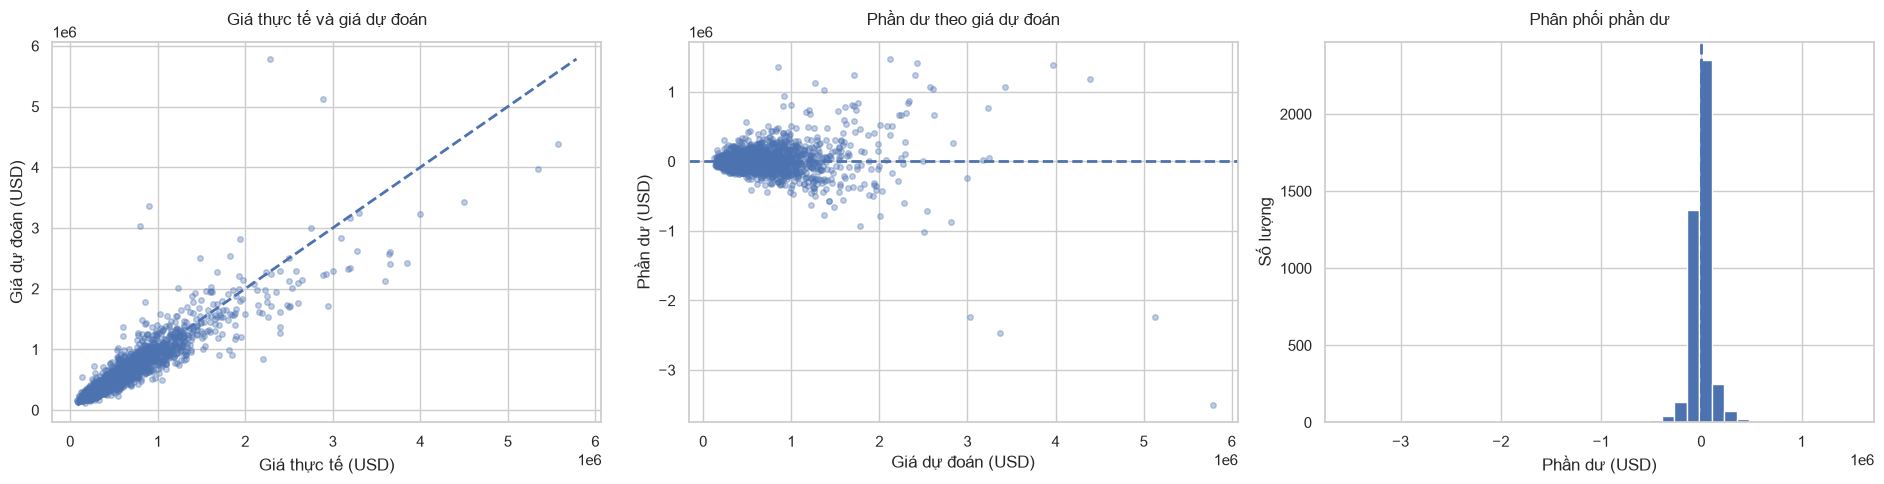

,So_mau,Gia_thuc_te_trung_vi,MAE,Sai_so_trung_binh
Nhóm giá,,,,
"(82499.999, 299000.0]",876,"250,000.00","39,174.89","-24,496.43"
"(299000.0, 399000.0]",855,"345,000.00","37,284.55","-10,419.26"
"(399000.0, 525000.0]",880,"455,750.00","46,864.29","-10,225.94"
"(525000.0, 711360.0]",847,"603,500.00","64,924.82","2,836.44"
"(711360.0, 5570000.0]",865,"895,000.00","178,205.93","55,137.16"


10 dự đoán có sai số tuyệt đối lớn nhất:


,Giá thực tế (USD),Giá dự đoán (USD),Sai số (USD),Sai số tuyệt đối (USD)
12777,"2,280,000.00","5,784,438.66","-3,504,438.66","3,504,438.66"
21050,"900,000.00","3,365,884.56","-2,465,884.56","2,465,884.56"
14556,"2,888,000.00","5,126,947.04","-2,238,947.04","2,238,947.04"
4024,"800,000.00","3,033,597.92","-2,233,597.92","2,233,597.92"
2864,"3,600,000.00","2,126,425.73","1,473,574.27","1,473,574.27"
2085,"3,850,000.00","2,428,214.31","1,421,785.69","1,421,785.69"
1448,"5,350,000.00","3,966,210.05","1,383,789.95","1,383,789.95"
19684,"2,205,000.00","847,626.57","1,357,373.43","1,357,373.43"
6508,"3,650,000.00","2,407,329.97","1,242,670.03","1,242,670.03"
20535,"2,950,000.00","1,708,296.63","1,241,703.37","1,241,703.37"


c:\Users\admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['waterfront' 'condition']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


,Đặc trưng,Mức tăng RMSE trung bình khi xáo trộn,Độ lệch chuẩn
12,lat,"80,719.88","2,298.70"
8,grade,"58,461.25","2,927.35"
2,sqft_living,"48,126.57",854.32
11,zipcode,"28,568.44",978.22
13,long,"17,955.73","2,167.83"
18,house_age_at_sale,"14,313.96","1,071.82"
6,view,"13,416.20","1,331.83"
14,sqft_living15,"5,091.68","1,990.95"
9,sqft_above,"3,370.80",836.29
16,sale_year,771.93,276.16


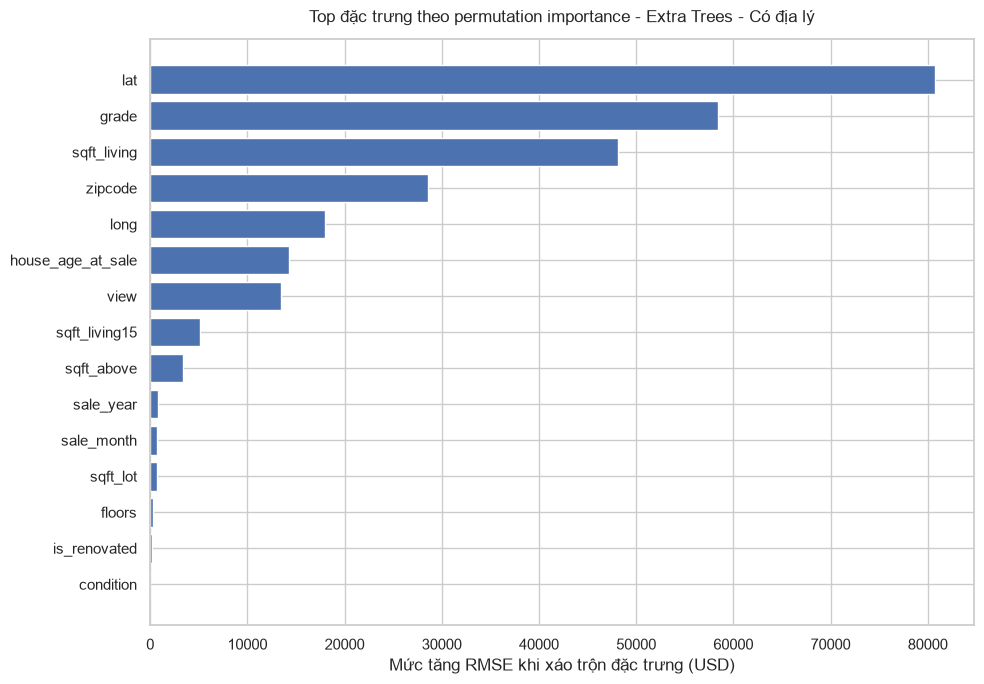

Kết luận đánh giá cần dựa trên: so sánh với Baseline, các metric trên test, biểu đồ phần dư, sai số theo nhóm giá và permutation importance. Không suy diễn các mức quan trọng thành quan hệ nhân quả.


In [18]:
# 15. Model Evaluation: sai số, phần dư, nhóm giá và feature importance
# 15.1. So sánh giá thực tế với dự đoán từ mô hình tốt nhất.
evaluation_detail = pd.DataFrame({
    'Giá thực tế (USD)': np.asarray(y_test),
    'Giá dự đoán (USD)': np.asarray(best_predictions)
}, index=y_test.index)

evaluation_detail['Sai số (USD)'] = (
    evaluation_detail['Giá thực tế (USD)']
    - evaluation_detail['Giá dự đoán (USD)']
)
evaluation_detail['Sai số tuyệt đối (USD)'] = (
    evaluation_detail['Sai số (USD)'].abs()
)

display(evaluation_detail.head(10).round(2))

best_metrics = model_evaluation.loc[
    model_evaluation['Mô hình'] == best_model_name
].drop(columns='Mô hình')
print(f'Metrics của mô hình tốt nhất: {best_model_name}')
display(best_metrics.round(3))

# 15.2. Chẩn đoán dự đoán và phần dư.
actual_values = evaluation_detail['Giá thực tế (USD)']
predicted_values = evaluation_detail['Giá dự đoán (USD)']
residuals = evaluation_detail['Sai số (USD)']

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
min_value = min(actual_values.min(), predicted_values.min())
max_value = max(actual_values.max(), predicted_values.max())

axes[0].scatter(actual_values, predicted_values, alpha=0.35, s=16)
axes[0].plot(
    [min_value, max_value], [min_value, max_value],
    linestyle='--', linewidth=2
)
axes[0].set_title('Giá thực tế và giá dự đoán')
axes[0].set_xlabel('Giá thực tế (USD)')
axes[0].set_ylabel('Giá dự đoán (USD)')

axes[1].scatter(predicted_values, residuals, alpha=0.35, s=16)
axes[1].axhline(0, linestyle='--', linewidth=2)
axes[1].set_title('Phần dư theo giá dự đoán')
axes[1].set_xlabel('Giá dự đoán (USD)')
axes[1].set_ylabel('Phần dư (USD)')

axes[2].hist(residuals, bins=40, edgecolor='white')
axes[2].axvline(0, linestyle='--', linewidth=2)
axes[2].set_title('Phân phối phần dư')
axes[2].set_xlabel('Phần dư (USD)')
axes[2].set_ylabel('Số lượng')

plt.tight_layout()
plt.show()

# 15.3. Đánh giá sai số theo các nhóm giá thực tế.
error_by_price_group = evaluation_detail.copy()
error_by_price_group['Nhóm giá'] = pd.qcut(
    error_by_price_group['Giá thực tế (USD)'],
    q=5,
    duplicates='drop'
)

error_group_summary = error_by_price_group.groupby(
    'Nhóm giá', observed=True
).agg(
    So_mau=('Giá thực tế (USD)', 'size'),
    Gia_thuc_te_trung_vi=('Giá thực tế (USD)', 'median'),
    MAE=('Sai số tuyệt đối (USD)', 'mean'),
    Sai_so_trung_binh=('Sai số (USD)', 'mean')
).round(2)

display(error_group_summary)

# 15.4. Xem các quan sát có sai số tuyệt đối lớn nhất.
print('10 dự đoán có sai số tuyệt đối lớn nhất:')
display(
    evaluation_detail
    .sort_values('Sai số tuyệt đối (USD)', ascending=False)
    .head(10)
    .round(2)
)

# 15.5. Permutation importance: đo mức tăng RMSE khi xáo trộn từng đặc trưng.
# Chọn đúng ma trận X_test tương ứng với mô hình tốt nhất (có/không địa lý).
if best_pipeline is not None:
    best_X_test = best_model_info['X_test']
    permutation_result = permutation_importance(
        best_pipeline,
        best_X_test,
        y_test,
        scoring='neg_root_mean_squared_error',
        n_repeats=3,
        random_state=42,
        n_jobs=-1
    )

    feature_importance = pd.DataFrame({
        'Đặc trưng': best_X_test.columns,
        'Mức tăng RMSE trung bình khi xáo trộn': permutation_result.importances_mean,
        'Độ lệch chuẩn': permutation_result.importances_std
    }).sort_values(
        'Mức tăng RMSE trung bình khi xáo trộn', ascending=False
    )

    display(feature_importance.head(20).round(4))

    top_features = feature_importance.head(15).sort_values(
        'Mức tăng RMSE trung bình khi xáo trộn', ascending=True
    )
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(
        top_features['Đặc trưng'],
        top_features['Mức tăng RMSE trung bình khi xáo trộn']
    )
    ax.set_title(f'Top đặc trưng theo permutation importance - {best_model_name}')
    ax.set_xlabel('Mức tăng RMSE khi xáo trộn đặc trưng (USD)')
    plt.tight_layout()
    plt.show()
else:
    print(
        'Baseline không có bộ đặc trưng để tính feature importance. '
        'Cần chọn một mô hình học được để phân tích vai trò của các biến.'
    )

print(
    'Kết luận đánh giá cần dựa trên: so sánh với Baseline, các metric trên test, '
    'biểu đồ phần dư, sai số theo nhóm giá và permutation importance. '
    'Không suy diễn các mức quan trọng thành quan hệ nhân quả.'
)